# Графический подход к множественному тестированию в A/B-экспериментаъ

## 0. Реализация класса `Graph`

In [30]:
import numpy as np
import networkx as nx
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from fractions import Fraction
from IPython.display import display, Markdown, Math
# -------------------------------------------------------------------
# Вспомогательные функции
# -------------------------------------------------------------------

def format_fraction(value, limit=1000):
    """Преобразует float в строку с обыкновенной дробью."""
    if value == 0:
        return "0"
    if value == 1:
        return "1"
    frac = Fraction(value).limit_denominator(limit)
    return f"{frac.numerator}/{frac.denominator}"

def update_graph(alpha_vec, G_matrix, rejected_idx):
    """
    Обновляет граф после отвержения гипотезы rejected_idx.
    Реализует формулы (2)-(3) из статьи Bretz et al. (2009).
    """
    m = len(alpha_vec)
    new_alpha = np.copy(alpha_vec)
    new_G = np.copy(G_matrix)

    rejected_alpha = alpha_vec[rejected_idx]
    new_alpha[rejected_idx] = 0.0

    # Перераспределение уровня по исходящим рёбрам (без проверки на >0)
    for l in range(m):
        if l != rejected_idx:
            new_alpha[l] += rejected_alpha * G_matrix[rejected_idx, l]

    # Обновление матрицы переходов
    for l in range(m):
        for k in range(m):
            if l != k and l != rejected_idx and k != rejected_idx:
                denominator = 1.0 - G_matrix[l, rejected_idx] * G_matrix[rejected_idx, l]
                if denominator > 0:
                    numerator = G_matrix[l, k] + G_matrix[l, rejected_idx] * G_matrix[rejected_idx, k]
                    new_G[l, k] = numerator / denominator
                else:
                    new_G[l, k] = 0.0
            else:
                new_G[l, k] = 0.0

    new_G[rejected_idx, :] = 0.0
    new_G[:, rejected_idx] = 0.0

    # Нормализация строк (сумма ≤ 1)
    for l in range(m):
        row_sum = np.sum(new_G[l, :])
        if row_sum > 1.0:
            new_G[l, :] /= row_sum

    return new_alpha, new_G

def draw_graph(alpha_vec, G_matrix,
               title="Графическое представление гипотез",
               width=800, height=600,
               show_alpha_values=True,
               alpha_symbol="α",
               node_labels=None):
    m = len(alpha_vec)
    if node_labels is None:
        node_labels = [f"H{i+1}" for i in range(m)]

    G = nx.DiGraph()
    for i in range(m):
        G.add_node(i, weight=alpha_vec[i], label=node_labels[i])
    for i in range(m):
        for j in range(m):
            if G_matrix[i, j] > 0 and i != j:
                G.add_edge(i, j, weight=G_matrix[i, j])

    # Расположение вершин
    if m == 1:
        pos = {0: np.array([0, 0])}
    elif m == 2:
        pos = {0: np.array([-1, 0]), 1: np.array([1, 0])}
    elif m == 3:
        pos = {0: np.array([0, np.sqrt(3)/2]),
               1: np.array([-0.8, -np.sqrt(3)/4]),
               2: np.array([0.8, -np.sqrt(3)/4])}
    elif m == 4:
        pos = {0: np.array([-1, 1]),
               1: np.array([1, 1]),
               2: np.array([1, -1]),
               3: np.array([-1, -1])}
    else:
        pos = nx.kamada_kawai_layout(G)

    fig = go.Figure()
    vertex_colors = ['#4C78A8', '#F58518', '#E45756', '#72B7B2',
                     '#54A24B', '#EECA3B', '#B279A2', '#FF9DA6']

    drawn_reverse = set()

    # Вспомогательная функция: добавление линии ребра и стрелки
    def add_edge_line(x0, y0, x1, y1, weight_str, u_label, v_label):
        """Рисует прямую линию со стрелкой и подпись веса."""
        # Линия
        fig.add_trace(go.Scatter(
            x=[x0, x1], y=[y0, y1],
            mode='lines',
            line=dict(color='rgba(100,100,100,0.7)', width=2),
            hoverinfo='text',
            text=f"{u_label} → {v_label}<br>Вес: {weight_str}",
            showlegend=False
        ))
        # Стрелка на конце
        fig.add_annotation(
            x=x1, y=y1,
            ax=x0, ay=y0,
            xref='x', yref='y',
            axref='x', ayref='y',
            showarrow=True,
            arrowhead=2,
            arrowsize=1.5,
            arrowwidth=2,
            arrowcolor='rgba(100,100,100,0.7)',
            text=""
        )
        # Подпись веса (середина ребра с небольшим сдвигом)
        mid_x, mid_y = (x0+x1)/2, (y0+y1)/2
        dx, dy = x1-x0, y1-y0
        dist = np.hypot(dx, dy)
        if dist > 0:
            offset_x = -dy/dist * 0.15
            offset_y = dx/dist * 0.15
        else:
            offset_x, offset_y = 0, 0
        fig.add_annotation(
            x=mid_x+offset_x, y=mid_y+offset_y,
            text=f"<b>{weight_str}</b>",
            showarrow=False,
            font=dict(size=11, color='#2c3e50'),
            bgcolor='rgba(255,255,255,0.9)',
            borderpad=4, borderwidth=1,
            bordercolor='rgba(128,128,128,0.3)'
        )

    # Рёбра
    for u, v in G.edges():
        has_reverse = (v, u) in G.edges()
        if has_reverse and (v, u) in drawn_reverse:
            continue

        x0, y0 = pos[u]
        x1, y1 = pos[v]
        weight = G.edges[u, v]['weight']
        weight_str = format_fraction(weight)

        if has_reverse:
            rev_weight = G.edges[v, u]['weight']
            rev_weight_str = format_fraction(rev_weight)
            curvature = 0.3
            dx = x1 - x0
            dy = y1 - y0
            dist = np.hypot(dx, dy)
            if dist > 0:
                nx_vec = -dy / dist
                ny_vec = dx / dist
            else:
                nx_vec, ny_vec = 0, 0

            # Первое ребро (u -> v)
            cx1 = (x0 + x1) / 2 + nx_vec * curvature
            cy1 = (y0 + y1) / 2 + ny_vec * curvature
            t = np.linspace(0, 1, 100)
            bx1 = (1-t)**2 * x0 + 2*(1-t)*t * cx1 + t**2 * x1
            by1 = (1-t)**2 * y0 + 2*(1-t)*t * cy1 + t**2 * y1
            fig.add_trace(go.Scatter(x=bx1, y=by1, mode='lines',
                                     line=dict(color='rgba(100,100,100,0.7)', width=2),
                                     hoverinfo='text',
                                     text=f"{node_labels[u]} → {node_labels[v]}<br>Вес: {weight_str}",
                                     showlegend=False))
            fig.add_annotation(x=bx1[-1], y=by1[-1], ax=bx1[-2], ay=by1[-2],
                               showarrow=True, arrowhead=2, arrowsize=1.5,
                               arrowwidth=2, arrowcolor='rgba(100,100,100,0.7)')
            mid1 = len(t)//2
            fig.add_annotation(x=bx1[mid1] + nx_vec*curvature*0.5,
                               y=by1[mid1] + ny_vec*curvature*0.5,
                               text=f"<b>{weight_str}</b>", showarrow=False,
                               font=dict(size=11, color='#2c3e50'),
                               bgcolor='rgba(255,255,255,0.9)',
                               borderpad=4, borderwidth=1,
                               bordercolor='rgba(128,128,128,0.3)')

            # Второе ребро (v -> u)
            cx2 = (x0 + x1) / 2 - nx_vec * curvature
            cy2 = (y0 + y1) / 2 - ny_vec * curvature
            bx2 = (1-t)**2 * x1 + 2*(1-t)*t * cx2 + t**2 * x0
            by2 = (1-t)**2 * y1 + 2*(1-t)*t * cy2 + t**2 * y0
            fig.add_trace(go.Scatter(x=bx2, y=by2, mode='lines',
                                     line=dict(color='rgba(100,100,100,0.7)', width=2),
                                     hoverinfo='text',
                                     text=f"{node_labels[v]} → {node_labels[u]}<br>Вес: {rev_weight_str}",
                                     showlegend=False))
            fig.add_annotation(x=bx2[-1], y=by2[-1], ax=bx2[-2], ay=by2[-2],
                               showarrow=True, arrowhead=2, arrowsize=1.5,
                               arrowwidth=2, arrowcolor='rgba(100,100,100,0.7)')
            mid2 = len(t)//2
            fig.add_annotation(x=bx2[mid2] - nx_vec*curvature*0.5,
                               y=by2[mid2] - ny_vec*curvature*0.5,
                               text=f"<b>{rev_weight_str}</b>", showarrow=False,
                               font=dict(size=11, color='#2c3e50'),
                               bgcolor='rgba(255,255,255,0.9)',
                               borderpad=4, borderwidth=1,
                               bordercolor='rgba(128,128,128,0.3)')
            drawn_reverse.add((u, v))
        else:
            # Прямое ребро – теперь используем функцию add_edge_line
            add_edge_line(x0, y0, x1, y1, weight_str, node_labels[u], node_labels[v])

    # Вершины
    for i in range(m):
        x, y = pos[i]
        weight = alpha_vec[i]
        color = vertex_colors[i % len(vertex_colors)]
        w_str = format_fraction(weight)
        fig.add_trace(go.Scatter(x=[x], y=[y], mode='markers+text',
                                 marker=dict(size=45, color=color,
                                             line=dict(color='white', width=3),
                                             opacity=0.95),
                                 text=f"<b>{node_labels[i]}</b>",
                                 textposition='middle center',
                                 textfont=dict(size=14, color='white'),
                                 hovertext=f"{node_labels[i]}<br>α = {w_str}",
                                 hoverinfo='text',
                                 showlegend=False))
        if show_alpha_values and weight > 0:
            fig.add_annotation(x=x, y=y-0.22, text=f"<b>{w_str}</b>",
                               showarrow=False,
                               font=dict(size=12, color='#2c3e50'),
                               bgcolor='rgba(255,255,255,0.85)',
                               borderpad=4, borderwidth=1,
                               bordercolor='rgba(128,128,128,0.3)')
        elif show_alpha_values:
            fig.add_annotation(x=x, y=y-0.22, text="<b>0</b>",
                               showarrow=False,
                               font=dict(size=12, color='#95a5a6'),
                               bgcolor='rgba(255,255,255,0.85)', borderpad=4)

    fig.update_layout(title=dict(text=title, font=dict(size=18, color='#2c3e50'), x=0.5),
                      width=width, height=height,
                      showlegend=False,
                      plot_bgcolor='rgba(252,252,252,1)',
                      paper_bgcolor='white',
                      xaxis=dict(showgrid=False, zeroline=False, showticklabels=False,
                                 scaleanchor='y', scaleratio=1),
                      yaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
                      margin=dict(t=80, b=40, l=40, r=40))
    fig.update_xaxes(range=[-1.6, 1.6])
    fig.update_yaxes(range=[-1.4, 1.4])
    return fig

In [31]:
# -------------------------------------------------------------------
# Класс Graph
# -------------------------------------------------------------------

class Graph:
    def __init__(self, m, alpha, alpha_vec, p_values, G_matrix):
        self.m = m
        self.alpha = alpha
        self.alpha_vec0 = np.array(alpha_vec, dtype=float)
        self.p_values = np.array(p_values, dtype=float)
        self.G0 = np.array(G_matrix, dtype=float)

        assert len(self.alpha_vec0) == m
        assert len(self.p_values) == m
        assert self.G0.shape == (m, m)
        assert np.sum(self.alpha_vec0) <= alpha + 1e-10, \
               f"Сумма начальных α ({np.sum(self.alpha_vec0)}) превышает общий уровень ({alpha})"

        self.reset()

    def reset(self):
        self.active = set(range(self.m))
        self.current_alpha = self.alpha_vec0.copy()
        self.current_G = self.G0.copy()
        self.rejected = set()
        self.history = []

    def _draw_state(self, alpha_vec, G_matrix, active_set, title,
                    width=700, height=500, show_alpha_values=True, alpha_symbol="α"):
        active_idx = sorted(active_set)
        if not active_idx:
            display(Markdown("Все гипотезы отвергнуты, граф пуст."))
            return
        sub_alpha = alpha_vec[active_idx]
        sub_G = G_matrix[np.ix_(active_idx, active_idx)]
        labels = [f"H{i+1}" for i in active_idx]
        fig = draw_graph(sub_alpha, sub_G,
                         title=title,
                         node_labels=labels,
                         width=width, height=height,
                         show_alpha_values=show_alpha_values,
                         alpha_symbol=alpha_symbol)
        fig.show()

    def draw_initial_graph(self,
                           title="Начальный граф",
                           width=1400,
                           height=600,
                           show_alpha_values=True,
                           alpha_symbol="α"):
        self._draw_state(self.alpha_vec0, self.G0, set(range(self.m)),
                         title=title, width=width, height=height,
                         show_alpha_values=show_alpha_values,
                         alpha_symbol=alpha_symbol)

    def print_analysis_steps(self, verbose=True):
        """Текстовое пошаговое тестирование с улучшенным форматированием."""
        self.reset()
        step = 0

        if verbose:
            display(Markdown("## 🧪 Запуск графического тестирования"))
            # p-значения – список
            p_list = "[" + ", ".join(f"{p:.4f}" for p in self.p_values) + "]"
            display(Markdown(f"**Исходные p-значения:** {p_list}"))
            # Исходные локальные α – тоже список (как p-значения)
            alpha_list = "[" + ", ".join(f"{format_fraction(self.alpha_vec0[i])}" for i in range(self.m)) + "]"
            display(Markdown(f"**Исходные локальные α:** {alpha_list}"))
            display(Markdown(f"**Общий уровень α:** {self.alpha}"))

        while self.active:
            step += 1
            active_list = sorted(self.active)
            I_label = f"I_{{{step-1}}}"

            if verbose:
                # Горизонтальная черта перед каждым шагом (кроме первого)
                if step > 1:
                    display(Markdown("---"))
                # Заголовок шага с множеством гипотез
                indices_str = ", ".join(str(i+1) for i in active_list)
                display(Markdown(f"### Шаг {step}. Рассматриваемые гипотезы: ${I_label} = \\{{{indices_str}\\}}$"))

                # Таблица (Markdown)
                header = "| Показатель | " + " | ".join([f"$H_{{{i+1}}}$" for i in active_list]) + " |"
                separator = "|" + "|".join([" --- "] * (len(active_list)+1)) + "|"
                p_row = "| $p$-значения | " + " | ".join([f"{self.p_values[i]:.4f}" for i in active_list]) + " |"
                alpha_row = f"| Локальные $\\alpha({I_label})$ | " + " | ".join([f"${format_fraction(self.current_alpha[i])}$" for i in active_list]) + " |"
                w_row = f"| Веса $w_i({I_label}) = \\alpha_i({I_label}) / \\alpha$ | " + " | ".join([f"${format_fraction(self.current_alpha[i]/self.alpha)}$" for i in active_list]) + " |"
                table_md = "\n".join([header, separator, p_row, alpha_row, w_row])
                display(Markdown(table_md))

            candidates = [(i, self.p_values[i] / self.current_alpha[i])
                          for i in active_list if self.current_alpha[i] > 0]
            if not candidates:
                if verbose:
                    display(Markdown("Нет гипотез с положительным уровнем α. Остановка."))
                break

            j, min_ratio = min(candidates, key=lambda x: x[1])

            if verbose:
                # Явно подставляем номер гипотезы j+1 в индексы
                p_j_label = f"p_{{{j+1}}}"
                alpha_j_label = f"\\alpha_{{{j+1}}}"
                condition = f"{p_j_label} \\le {alpha_j_label}" if self.p_values[j] <= self.current_alpha[j] else f"{p_j_label} > {alpha_j_label}"
                outcome = "ОТВЕРГАЕТСЯ" if self.p_values[j] <= self.current_alpha[j] else "НЕ отвергается"
                emoji = "✅" if self.p_values[j] <= self.current_alpha[j] else "❌"
                display(Markdown(
                    f"**2.** Наименьшее отношение $p/\\alpha$ у гипотезы $H_{{{j+1}}}$: "
                    f"{self.p_values[j]:.4f} / {format_fraction(self.current_alpha[j])} = {min_ratio:.4f}. "
                    f"${condition}$ → **Гипотеза $H_{{{j+1}}}$ {outcome}** {emoji}"
                ))

            if self.p_values[j] <= self.current_alpha[j]:
                self.history.append({
                    'step': step,
                    'rejected_hyp': j,
                    'active_before': set(self.active),
                    'alpha_before': self.current_alpha.copy(),
                    'G_before': self.current_G.copy()
                })
                self.rejected.add(j)
                self.active.remove(j)
                old_alpha = self.current_alpha.copy()
                self.current_alpha, self.current_G = update_graph(self.current_alpha,
                                                                  self.current_G, j)
                if verbose:
                    display(Markdown("**3. Обновление графа:**"))
                    new_active = sorted(self.active)
                    if new_active:
                        # Пересчёт α
                        new_alpha_str = ", ".join(
                            [f"$\\alpha_{{{i+1}}} = {format_fraction(self.current_alpha[i])}$" for i in new_active]
                        )
                        display(Markdown(f"  * **Пересчитываем α:** [{new_alpha_str}]"))
                        # Пересчёт матрицы переходов
                        sub_G = self.current_G[np.ix_(new_active, new_active)]
                        n_dim = sub_G.shape[0]
                        if n_dim > 0:
                            latex_matrix = r"\begin{pmatrix}" + " \\\\ ".join(
                                " & ".join(f"{val:.4g}" if val != 0 else "0" for val in row) for row in sub_G
                            ) + r"\end{pmatrix}"
                            display(Markdown("  * **Пересчитываем матрицу переходов G:**"))
                            display(Math(latex_matrix))
                        else:
                            display(Markdown("  * Матрица переходов пуста."))
                    else:
                        display(Markdown("  * Все гипотезы отвергнуты."))
            else:
                if verbose:
                    display(Markdown("Процедура останавливается, так как условие не выполнено."))
                break

        if verbose:
            display(Markdown("\n---\n### Результаты"))
            rejected_list = ", ".join([f"$H_{{{i+1}}}$" for i in sorted(self.rejected)])
            not_rejected_list = ", ".join([f"$H_{{{i+1}}}$" for i in range(self.m) if i not in self.rejected])
            display(Markdown(f"**Отвергнутые гипотезы:** {rejected_list}"))
            display(Markdown(f"**Не отвергнутые:** {not_rejected_list}"))

        return self.rejected

    def draw_analysis_steps(self, title="Шаги анализа", width=1400, height=600,
                            show_alpha_values=True, alpha_symbol="α"):
        if not self.history:
            display(Markdown("История пуста. Сначала запустите тестирование."))
            return

        n = len(self.history)
        fig = make_subplots(rows=1, cols=n, subplot_titles=[f"Шаг {h['step']}" for h in self.history],
                            horizontal_spacing=0.05)

        for idx, entry in enumerate(self.history):
            rej = entry['rejected_hyp']
            alpha_after, G_after = update_graph(entry['alpha_before'],
                                                entry['G_before'], rej)
            active_after = entry['active_before'] - {rej}
            active_idx = sorted(active_after)
            if not active_idx:
                continue

            sub_alpha = alpha_after[active_idx]
            sub_G = G_after[np.ix_(active_idx, active_idx)]
            labels = [f"H{i+1}" for i in active_idx]

            tmp_fig = draw_graph(sub_alpha, sub_G,
                                 title="",
                                 node_labels=labels,
                                 width=width//n, height=height,
                                 show_alpha_values=show_alpha_values,
                                 alpha_symbol=alpha_symbol)
            for trace in tmp_fig.data:
                fig.add_trace(trace, row=1, col=idx+1)
            for annotation in tmp_fig.layout.annotations:
                annotation.xref = f'x{idx+1}'
                annotation.yref = f'y{idx+1}'
                fig.add_annotation(annotation)

        fig.update_layout(
            title=dict(text=title, font=dict(size=18, color='#2c3e50'), x=0.5),
            width=width, height=height,
            showlegend=False,
            plot_bgcolor='rgba(252,252,252,1)',
            paper_bgcolor='white',
            margin=dict(t=80, b=40, l=40, r=40)
        )
        for i in range(1, n+1):
            fig.update_xaxes(showgrid=False, zeroline=False, showticklabels=False, row=1, col=i)
            fig.update_yaxes(showgrid=False, zeroline=False, showticklabels=False, row=1, col=i)

        fig.show()

    def run_full_analysis(self, title="Полный анализ", width=1400, height=600,
                          show_alpha_values=True, alpha_symbol="α"):
        self.reset()
        step = 0

        display(Markdown("## 🚀 Полное тестирование с визуализацией"))
        # p-значения списком
        p_list = "[" + ", ".join(f"{p:.4f}" for p in self.p_values) + "]"
        display(Markdown(f"**Исходные p-значения:** {p_list}"))
        # Исходные локальные α списком
        alpha_list = "[" + ", ".join(f"{format_fraction(self.alpha_vec0[i])}" for i in range(self.m)) + "]"
        display(Markdown(f"**Исходные локальные α:** {alpha_list}"))
        display(Markdown(f"**α = {self.alpha}**"))

        self.draw_initial_graph(title="Начальный граф", width=width, height=height,
                                show_alpha_values=show_alpha_values, alpha_symbol=alpha_symbol)

        while self.active:
            step += 1
            active_list = sorted(self.active)
            I_label = f"I_{{{step-1}}}"

            # Горизонтальный разделитель между шагами (кроме первого, но здесь всегда после первого шага уже есть вывод)
            if step > 1:
                display(Markdown("---"))

            # Заголовок шага
            indices_str = ", ".join(str(i+1) for i in active_list)
            display(Markdown(f"### Шаг {step}. Рассматриваемые гипотезы: ${I_label} = \\{{{indices_str}\\}}$"))

            # Таблица
            header = "| Показатель | " + " | ".join([f"$H_{{{i+1}}}$" for i in active_list]) + " |"
            separator = "|" + "|".join([" --- "] * (len(active_list)+1)) + "|"
            p_row = "| $p$-значения | " + " | ".join([f"{self.p_values[i]:.4f}" for i in active_list]) + " |"
            alpha_row = f"| Локальные $\\alpha({I_label})$ | " + " | ".join([f"${format_fraction(self.current_alpha[i])}$" for i in active_list]) + " |"
            w_row = f"| Веса $w_i({I_label}) = \\alpha_i({I_label}) / \\alpha$ | " + " | ".join([f"${format_fraction(self.current_alpha[i]/self.alpha)}$" for i in active_list]) + " |"
            table_md = "\n".join([header, separator, p_row, alpha_row, w_row])
            display(Markdown(table_md))

            candidates = [(i, self.p_values[i] / self.current_alpha[i])
                          for i in active_list if self.current_alpha[i] > 0]
            if not candidates:
                display(Markdown("Нет гипотез с положительным уровнем α. Остановка."))
                break

            j, min_ratio = min(candidates, key=lambda x: x[1])

            # Пункт 2: конкретные индексы
            p_j_label = f"p_{{{j+1}}}"
            alpha_j_label = f"\\alpha_{{{j+1}}}"
            condition = f"{p_j_label} \\le {alpha_j_label}" if self.p_values[j] <= self.current_alpha[j] else f"{p_j_label} > {alpha_j_label}"
            outcome = "ОТВЕРГАЕТСЯ" if self.p_values[j] <= self.current_alpha[j] else "НЕ отвергается"
            emoji = "✅" if self.p_values[j] <= self.current_alpha[j] else "❌"
            display(Markdown(
                f"**2.** Наименьшее отношение $p/\\alpha$ у гипотезы $H_{{{j+1}}}$: "
                f"{self.p_values[j]:.4f} / {format_fraction(self.current_alpha[j])} = {min_ratio:.4f}. "
                f"${condition}$ → **Гипотеза $H_{{{j+1}}}$ {outcome}** {emoji}"
            ))

            if self.p_values[j] <= self.current_alpha[j]:
                # Отвержение и обновление
                self.rejected.add(j)
                self.active.remove(j)
                old_alpha = self.current_alpha.copy()
                old_G = self.current_G.copy()
                self.current_alpha, self.current_G = update_graph(self.current_alpha,
                                                                  self.current_G, j)
                self.history.append({
                    'step': step,
                    'rejected_hyp': j,
                    'active_before': set(self.active) | {j},
                    'alpha_before': old_alpha,
                    'G_before': old_G
                })

                # Пункт 3
                display(Markdown("**3. Обновление графа:**"))
                new_active = sorted(self.active)
                if new_active:
                    new_alpha_str = ", ".join(
                        [f"$\\alpha_{{{i+1}}} = {format_fraction(self.current_alpha[i])}$" for i in new_active]
                    )
                    display(Markdown(f"  * **Пересчитываем α:** [{new_alpha_str}]"))
                    sub_G = self.current_G[np.ix_(new_active, new_active)]
                    n_dim = sub_G.shape[0]
                    if n_dim > 0:
                        latex_matrix = r"\begin{pmatrix}" + " \\\\ ".join(
                            " & ".join(f"{val:.4g}" if val != 0 else "0" for val in row) for row in sub_G
                        ) + r"\end{pmatrix}"
                        display(Markdown("  * **Пересчитываем матрицу переходов G:**"))
                        display(Math(latex_matrix))
                    else:
                        display(Markdown("  * Матрица переходов пуста."))
                else:
                    display(Markdown("  * Все гипотезы отвергнуты."))

                # Визуализация графа после шага
                self._draw_state(self.current_alpha, self.current_G, self.active,
                                 title=f"Шаг {step}: после отвержения $H_{{{j+1}}}$",
                                 width=width, height=height,
                                 show_alpha_values=show_alpha_values,
                                 alpha_symbol=alpha_symbol)
            else:
                break

        display(Markdown("\n---\n### Результаты"))
        rejected_list = ", ".join([f"$H_{{{i+1}}}$" for i in sorted(self.rejected)])
        not_rejected_list = ", ".join([f"$H_{{{i+1}}}$" for i in range(self.m) if i not in self.rejected])
        display(Markdown(f"**Отвергнутые гипотезы:** {rejected_list}"))
        display(Markdown(f"**Не отвергнутые:** {not_rejected_list}"))
        return self.rejected

In [3]:
# Пример использования
alpha = 0.05
m = 4
alpha_vec = np.full(m, alpha/m)
g_weight = 1.0 / (m - 1)
G = np.full((m, m), g_weight)
np.fill_diagonal(G, 0)
p_vals = np.array([0.02, 0.055, 0.012, 0.012])

graph = Graph(m, alpha, alpha_vec, p_vals, G)

In [4]:
graph.draw_initial_graph(title="Полный анализ", width=1400, height=600,
                         show_alpha_values=True, alpha_symbol="α")

In [5]:
graph.print_analysis_steps()

## 🧪 Запуск графического тестирования

**Исходные p-значения:** [0.0200, 0.0550, 0.0120, 0.0120]

**Исходные локальные α:** [1/80, 1/80, 1/80, 1/80]

**Общий уровень α:** 0.05

### Шаг 1. Рассматриваемые гипотезы: $I_{0} = \{1, 2, 3, 4\}$

...

Процедура останавливается, так как условие не выполнено.


---
### Результаты

**Отвергнутые гипотезы:** $H_{1}$, $H_{3}$, $H_{4}$

**Не отвергнутые:** $H_{2}$

{0, 2, 3}

In [6]:
graph.draw_analysis_steps(title="Полный анализ", width=1400, height=600,
                          show_alpha_values=True, alpha_symbol="α")

In [7]:
graph.run_full_analysis(title="Полный анализ", width=1000, height=400,
                        show_alpha_values=False, alpha_symbol="α")

## 🚀 Полное тестирование с визуализацией

**Исходные p-значения:** [0.0200, 0.0550, 0.0120, 0.0120]

**Исходные локальные α:** [1/80, 1/80, 1/80, 1/80]

**α = 0.05**

### Шаг 1. Рассматриваемые гипотезы: $I_{0} = \{1, 2, 3, 4\}$

...

**2.** Наименьшее отношение $p/\alpha$ у гипотезы $H_{2}$: 0.0550 / 1/20 = 1.1000. $p_{2} > \alpha_{2}$ → **Гипотеза $H_{2}$ НЕ отвергается** ❌


---
### Результаты

**Отвергнутые гипотезы:** $H_{1}$, $H_{3}$, $H_{4}$

**Не отвергнутые:** $H_{2}$

{0, 2, 3}

## 1. Введение и напоминание базовых концепций

### 1.1 Краткое напоминание: FWER, FDR и классические поправки

Прежде чем мы погрузимся в графический подход, давайте освежим в памяти тот фундамент, на котором всё строится. Вы уже знакомы с проблемой множественных сравнений и основными методами её решения, поэтому быстро пройдёмся по ключевым понятиям, но обязательно выделим те ограничения классических процедур, которые как раз и мотивировали создание графического подхода.

Итак, представим, что в рамках одного A/B‑эксперимента или клинического исследования мы проверяем не одну, а сразу несколько нулевых гипотез: скажем, сравниваем несколько вариантов продукта по нескольким метрикам, или анализируем несколько конечных точек эффективности и безопасности. Классический пример из области, которую мы будем рассматривать, — клиническое исследование с двумя дозами препарата, тремя иерархически упорядоченными конечными точками, итого шесть элементарных гипотез. Или, что ближе вам, A/B‑тест с контролем и тремя вариантами, где у каждого варианта есть основная метрика — выручка, и несколько guadrail метрик, например, CTR и retention. Возникает вопрос: как нам принять решение по всему этому набору гипотез, сохраняя контроль над ошибками?

Проблема хорошо известна: если каждую из $m$ независимых нулевых гипотез проверять на привычном уровне значимости $\alpha$ (например, $0.05$), то вероятность совершить хотя бы одну ошибку I рода стремительно растёт. Формально:

$$
P(\text{хотя бы одна ошибка I рода}) = 1 - (1 - \alpha)^m\;.
$$

При $m = 10$ и $\alpha = 0.05$ эта вероятность уже около $0.40$, при $m = 20$ — порядка $0.64$. Иными словами, мы почти наверняка найдём какое‑то «значимое» различие просто в силу случайности. Поэтому нам нужны специальные метрики и процедуры, которые удерживают общую вероятность ложных выводов в заданных рамках.

Центральных метрики три.

1. **Групповая вероятность ошибки I рода**, Family‑Wise Error Rate (FWER)

$$
FWER = P(V \ge 1)\;, \text{ где V — число ложноположительных результатов}
$$

Контроль FWER на уровне $\alpha$ означает, что при любом раскладе истинных и ложных гипотез вероятность допустить хотя бы одну такую ошибку не превышает $\alpha$. Этот критерий очень строг, и именно его требуют регуляторы для подтверждающих клинических испытаний, потому что главная цель — минимизировать риск пропуска на рынок неэффективного или небезопасного препарата.

2. **Доля ложных отклонений**, False Discovery Rate (FDR)

$$
FDR = \mathbb{E}\!\left[\frac{V}{\max(R,1)}\right]\;, \text{ где $R$ — общее число отвергнутых гипотез}
$$

Фактически FDR показывает, какую долю среди всех наших «находок» в среднем составляют ложные. Контроль на уровне, скажем, $0.05$ допускает, что в среднем 5% объявленных значимыми результатов будут ошибочными. Это более мягкий критерий, чем FWER, и он особенно популярен в задачах с тысячами гипотез, например, в геномике или нейровизуализации. В контексте A/B‑тестов он тоже может применяться на разведочных стадиях.

3. **Обобщённая FWER**, $k$‑FWER:

$$
k\text{-}FWER = P(V \ge k)\;.
$$

Она контролирует вероятность совершить $k$ или более ложных отклонений. При $k=1$ это обычный FWER. Увеличивая $k$, мы ослабляем контроль, но можем повысить мощность — это полезно, когда мы готовы мириться с одним‑двумя лишними ложными сигналами ради обнаружения большего числа реальных эффектов.

Теперь вспомним три классические процедуры, которые вы уже знаете. Все они оперируют упорядоченными p‑значениями: $p_{(1)} \le p_{(2)} \le \dots \le p_{(m)}$.

1. **Поправка Бонферрони** — отвергаем любую гипотезу $H_i$, для которой $p_i \le \alpha / m$. Она гарантирует $FWER \le \alpha$ без всяких предположений о зависимости p‑значений, но платит за это чрезвычайной консервативностью.

2. **Процедура Холма**: мы идём от самого маленького p‑значения к самому большому и сравниваем $p_{(i)}$ с порогом $\alpha/(m-i+1)$. Как только встречаем p‑значение, которое больше своего порога, останавливаемся и отвергаем только предыдущие. Процедура Холма также контролирует FWER без каких‑либо предположений о структуре зависимости и является более мощной, чем Бонферрони

3. **Процедура Бенджамини–Хохберг**: алгоритм почти такой же, но ищется наибольшее $k$, для которого $p_{(k)} \le \frac{k}{m}\,\alpha$, и отвергаются все гипотезы с индексами от $1$ до $k$. Эта процедура гарантировано контролирует FDR только при независимости p‑значений или при положительной регрессионной зависимости.


На первый взгляд, этого арсенала достаточно. Однако давайте задумаемся: все эти процедуры обращаются с гипотезами **симметрично** — каждая гипотеза изначально рассматривается как равноправная. Но в реальных задачах, особенно в клинических испытаниях и сложных A/B‑тестах, гипотезы почти никогда не равноправны. У нас есть первичные конечные точки, которые обязательно должны быть значимы, чтобы исследование считалось успешным, и вторичные, которые мы тестируем только при условии успеха первичных. Есть иерархия важности, есть логические связи: например, мы не будем проверять безопасность дозировки, если не доказана её эффективность. Или в A/B‑тестировании: сначала нужно убедиться, что новый интерфейс не уронил ключевую метрику продаж, а затем уже смотреть на вспомогательные метрики вовлечённости.

Ни Бонферрони, ни Холм, ни BH не позволяют естественным образом отразить такую логику. Они не знают, что уровень значимости, «сэкономленный» на отвержении какой‑то вторичной гипотезы, должен быть передан обратно в первичное семейство, или что начальные права на проверку должны быть распределены неравномерно. В результате исследователи либо вынуждены применять кустарные, не вполне обоснованные схемы, либо теряют мощность там, где она критически важна.

Именно для преодоления этих ограничений Франк Бретц и его коллеги в 2009 году предложили **графический подход**. Ключевая идея — представить всё семейство гипотез в виде ориентированного взвешенного графа, где:

* вершины (узлы) — это элементарные нулевые гипотезы $H_i$;
* каждой вершине приписан начальный вес $\alpha_i$, причём сумма всех $\alpha_i$ не превышает общий уровень значимости $\alpha$;
* направленные рёбра от $H_i$ к $H_j$ имеют вес $g_{ij}$, который показывает, какая доля локального уровня $\alpha_i$ будет передана гипотезе $H_j$ после того, как $H_i$ отвергнута.

Таким образом, при отвержении гипотезы её уровень не пропадает, а **перераспределяется** по заданным правилам на оставшиеся, ещё не проверенные гипотезы. Это даёт возможность построить **последовательно отвергающую процедуру**, которая:

1. строго контролирует FWER на уровне $\alpha$;
2. учитывает приоритеты и логическую иерархию между гипотезами;
3. часто оказывается мощнее классических аналогов именно за счёт разумного «рециклинга» уровня значимости;
4. и, что немаловажно, представляет сложную стратегию тестирования в виде интуитивно понятной картинки, которую легко обсуждать с коллегами и регуляторами.

В последующих разделах мы формализуем этот подход, изучим его связь с замкнутой процедурой тестирования и увидим, как простые изменения в топологии графа превращают его из процедуры Бонферрони в процедуру Холма, затем в различные варианты гейткипинга и даже в процедуры, контролирующие $k$‑FWER. А сейчас, прежде чем перейти к мотивации на конкретных примерах, зафиксируем главный тезис: **классические методы не умеют работать с иерархией гипотез; графический подход решает именно эту проблему, сохраняя строгий контроль над ошибками**.

### 1.2 Мотивация: от одного теста к сложному A/B-эксперименту

**Типичный A/B‑тест: больше не «один вариант — одна метрика»**

Ещё несколько лет назад типовой онлайн‑эксперимент выглядел так: у нас есть контрольная группа и один экспериментальный вариант, одна ключевая метрика успеха (скажем, конверсия в покупку) и несколько «охранных» метрик, которые мы проверяем на всякий случай. Сегодня же ландшафт гораздо сложнее. Рассмотрим несколько примеров, которые будем использовать на протяжении всей лекции.

**Пример 1. Три интерфейса корзины**
  
Предположим, продуктовая команда разработала три альтернативных интерфейса корзины: вариант A, вариант B и вариант C. Основная цель — увеличить средний чек. Одновременно нам критически важно не ухудшить пользовательский опыт: мы отслеживаем CTR на главную страницу, удержание (retention) через неделю и, возможно, время до первого заказа. Логика принятия решения такова:

1. Мы тестируем гипотезу о том, что вариант A превосходит контроль по revenue.  
2. Если это удалось доказать, только тогда мы проверяем, что A не ухудшает CTR, retention и время до заказа.  
3. Если же по revenue вариант A не значим, мы переходим к сравнению варианта B с контролем по revenue, и так далее.

Здесь мы имеем не плоское множество гипотез, а **двухуровневую иерархию**:
- **Первичный уровень:** три гипотезы о превосходстве по revenue для каждого варианта.
- **Вторичный уровень:** под каждой из этих гипотез висит семейство проверок на «не хуже» по вспомогательным метрикам.

**Пример 2. Клиническое исследование с множеством доз.**  

В статье Бретца и соавторов (2009), а также в кейсах второй статьи, рассматривается поздняя фаза разработки препарата для лечения рассеянного склероза. Задача: сравнить две дозы нового препарата с плацебо по трём иерархически упорядоченным конечным точкам: частота рецидивов, число очагов в мозге на МРТ и прогрессирование инвалидизации. Итого шесть элементарных гипотез: $[H_{i1}, H_{i2}, H_{i3}]\;, i \in [1,2]$ (если $i=1$, то  высокая доза, иначе -  низкая). Клиническая логика требует:

  - Если высокая доза не показала превосходства по первой, самой важной конечной точке, дальнейшее тестирование низкой дозы возможно, но с пониженным весом.
  - Успех по первой точке для высокой дозы «открывает ворота» к проверке второй точки, а затем третьей — в строгой последовательности.

**Пример 3. Многошаговый протокол «K из N».**


В исследовании Pre‑RELAX‑AHF требовалось доказать эффект экспериментального лечения по крайней мере на 6 из 9 заранее заданных конечных точек, связанных с острой сердечной недостаточностью. Лишь после выполнения этого условия разрешалось тестировать вторичные гипотезы безопасности. Здесь возникает ещё более сложная логическая связь: первичный успех определяется не одной гипотезой, а конъюнкцией («хотя бы шесть из девяти»).


**К чему приводит отсутствие учёта иерархии?**

Если мы воспользуемся классической процедурой Холма для всех гипотез одновременно, то каждый отдельный тест получит долю $\alpha$, пропорциональную общему числу гипотез, и порядок проверки будет диктоваться исключительно величиной p‑значений. Это порождает две серьёзные проблемы:

1. **Неэффективное распределение $\alpha$.**

Предположим, в примере с вариантами интерфейса самый маленький p‑value получился у варианта C по AOV, а следующий по величине — у варианта A по вспомогательной метрике. Процедура Холма потратит часть общего уровня $\alpha$ на проверку вспомогательной метрики варианта A, хотя вариант A ещё не доказал превосходства по основной метрике! Это противоречит бизнес‑логике: мы не должны «тратить» статистический бюджет на проверку безопасности того, что не доказало эффективность.

2. **Риск преждевременной остановки.**

Представьте себе фиксированную последовательность тестов (fixed sequence test), где все гипотезы выстроены в одну цепочку $(H_{11} \to H_{21} \to H_{12} \to \dots \to H_{23})$. Если первая гипотеза $H_{11}$ (высокая доза vs плацебо по relapse rate) не отвергается на уровне $\alpha$, процедура немедленно останавливается, и все остальные гипотезы, даже с очень маленькими p‑значениями, формально не могут быть отвергнуты. Исследование признаётся неуспешным полностью, хотя низкая доза, возможно, была эффективной. Жёсткая фиксация порядка тестирования, таким образом, приводит к неприемлемой потере мощности.

**Идея графического представления**

Графический подход преодолевает эти ограничения, предлагая мыслить о семействе гипотез как о **взвешенном ориентированном графе**, где рёбра несут в себе правила «наследования» уровня значимости. Вернёмся к примеру с двумя дозами и тремя endpoint’ами. Мы можем построить граф, в котором:

- Вершинам, соответствующим гипотезам эффективности первой (самой важной) конечной точки, присваиваются наибольшие начальные веса.
- Рёбра направлены от первичных гипотез к вторичным и от более важных endpoint’ов к менее важным.
- Веса рёбер определяют, как перераспределяется уровень $\alpha$ после отвержения той или иной гипотезы.

Например, мы можем договориться, что $\alpha$ распределяется поровну между двумя дозами, и внутри каждой дозы идёт фиксированная последовательность от первой конечной точки к третьей. Но в отличие от жёсткой фиксированной последовательности, если высокая доза «провалится», её доля $\alpha/2$ не пропадёт — она перетечёт на гипотезы низкой дозы! И наоборот, если высокая доза окажется успешной по всем трём endpoint’ам, освободившийся уровень может быть передан для усиления тестов низкой дозы. Эта гибкая система «рециклинга» значимости в точности отражает иерархическую логику принятия решений.

**Метафора «бюджета»**

Позвольте мне ввести интуитивную метафору, которая поможет нам мыслить о графическом подходе на протяжении всей лекции. Представьте, что общий уровень значимости \(\alpha\) — это бюджет, который спонсор исследования выделяет на проверку всех гипотез. Каждая вершина графа — это исследовательская группа, которой выделена определённая часть бюджета \((\alpha_i)\). Когда группа успешно завершает свою работу (гипотеза отвергается), она не кладёт оставшиеся деньги себе в карман, а переводит их следующей группе согласно заранее составленному плану (рёбра с весами \(g_{ij}\)). Более того, если какая‑то группа не справилась (гипотеза не отвергнута), она просто остаётся без финансирования, а её бюджет уже учтён в начальном распределении.

**Преимущества графического подхода — анонс**

Графический подход обладает тремя ключевыми достоинствами, которые делают его привлекательным и для клинических испытаний, и для онлайн‑экспериментов:

1. **Строгий контроль FWER.** Несмотря на всю гибкость, процедура гарантирует, что вероятность хотя бы одного ложного отклонения не превышает заданного $\alpha$. Математически это опирается на замкнутую процедуру тестирования, с которой мы познакомимся в разделе 2.3.

2. **Прозрачность и коммуницируемость.** Граф можно нарисовать на доске и обсудить с клинической командой или с продакт‑менеджерами. Им не нужно вникать в дебри длинных таблиц весов для всех $2^m - 1$ пересечений гипотез. Связи и приоритеты сразу видны.

3. **Гибкость и мощность.** За счёт перераспределения уровня значимости графические процедуры почти всегда мощнее или не уступают своим классическим аналогам, особенно когда гипотезы упорядочены. В дальнейшем мы увидим, как можно донастраивать графы с помощью $\varepsilon$-рёбер и расширений на случай контроля k-FWER и FDP (об этом пойдёт речь во второй части лекции, основанной на статье).

Прежде чем переходить к формальному описанию алгоритмов, давайте зафиксируем главный тезис этого блока: **в сложных A/B‑тестах и клинических исследованиях гипотезы образуют естественную иерархию; графический подход позволяет перенести эту иерархию на граф и затем автоматически построить корректную процедуру множественного тестирования, контролирующую FWER.** В следующем разделе мы наденем математические очки и строго определим все компоненты: вершины, веса, матрицу переходов и сам алгоритм.

## 2. Формальный аппарат графического подхода

### 2.1 Граф как математическая модель семейства гипотез

**Исходные ингредиенты**

Пусть у нас есть множество из $m$ элементарных нулевых гипотез, которые мы хотим проверить в рамках одного эксперимента: $H_1,\, H_2,\, \dots,\, H_m.$

Например, в уже знакомом примере с двумя дозами и тремя конечными точками $m = 6$; в A/B‑тесте с тремя вариантами и одной основной метрикой $m = 3$; если добавляются ещё и охранные метрики, $m$ растёт.

Мы работаем в рамках частотного подхода, и все наши дальнейшие построения будут гарантировать контроль FWER на уровне не выше заданного $\alpha \in (0,1)$.

ㅤ

**Первый ключевой объект — вектор начальных весов**

Назначим каждой гипотезе $H_i$ **начальный локальный уровень значимости** — неотрицательное число $\alpha_i \ge 0$. Вектор $\boldsymbol{\alpha} = (\alpha_1, \alpha_2, \dots, \alpha_m)$ должен удовлетворять единственному условию: сумма всех его компонент не превышает общий уровень $\alpha$:

$$
\sum_{i=1}^{m} \alpha_i \le \alpha.
$$

Это условие гарантирует, что начальное распределение «бюджета» в сумме не выходит за пределы выделенного лимита.

ㅤ

**Второй ключевой объект — матрица переходов**

Теперь нам нужно правило, которое говорит, куда переходят средства, выделенные на гипотезу $H_i$, после того как она отвергнута. Это правило задаётся квадратной матрицей $\mathbf{G} = (g_{ij})_{m \times m},$ где $g_{ij}$ — доля уровня $\alpha_i$, передаваемая от $H_i$ к $H_j$. На элементы матрицы $\mathbf{G}$ накладываются три естественных ограничения:

1. $0 \le g_{ij} \le 1$ для всех $i, j$ — веса являются долями, поэтому они лежат в отрезке $[0,1]$.
2. $g_{ii} = 0$ для всех $i$ — отвергнутая гипотеза не может передавать уровень самой себе (её вершина удаляется из графа).
3. $\sum_{k=1}^{m} g_{ik} \le 1$ для всех $i$ — сумма долей, исходящих из одной вершины, не должна превышать 1; это означает, что мы не можем раздать больше, чем имеем.

Таким образом, каждая строка матрицы $\mathbf{G}$ описывает, как будет потрачен уровень значимости соответствующей гипотезы в случае её отвержения.

Ограничения на $\mathbf{G}$ довольно мягкие: мы можем задавать практически любые доли переходов, лишь бы суммы строк не превышали единицу и диагональ была нулевой. Это даёт колоссальную гибкость: можно направить весь уровень отвергнутой первичной гипотезы на одну вторичную, можно распределить поровну между несколькими, а можно часть сознательно «сжечь» (оставив сумму исходящих весов строго меньше 1). Правила работы с такими графами — это и есть алгоритм, который мы формально опишем в следующем разделе 2.2.
ㅤ

**Интерпретация в виде графа**

Пара $(\boldsymbol{\alpha}, \mathbf{G})$ естественным образом задаёт **ориентированный взвешенный граф**:

- **Вершины** $V_1, \dots, V_m$ соответствуют элементарным гипотезам $H_1, \dots, H_m$.
- Вершина $V_i$ снабжена **весом** $\alpha_i$.
- Из вершины $V_i$ в вершину $V_j$ $(j \neq i)$ идёт направленное ребро с **весом** $g_{ij} > 0$. Если $g_{ij} = 0$, ребро отсутствует.

Петли при вершинах отсутствуют $(g_{ii} = 0)$, а сумма весов всех исходящих рёбер не превышает 1.

Эта графическая нотация и дала название всему подходу. Она позволяет буквально нарисовать стратегию тестирования и обсуждать её с коллегами, не углубляясь в матричные выкладки.

**Простой пример: процедура Холма для $m = 2$**

Давайте посмотрим на элементарный случай, который иллюстрирует все введённые понятия. Рассмотрим две гипотезы $H_1$ и $H_2$, которые мы хотим проверить, контролируя FWER на уровне $\alpha$. Процедура Холма для двух гипотез предписывает: **Отвергнуть ту гипотезу, у которой p‑значение меньше; если она отвергается на уровне $\alpha/2$, то оставшуюся проверять уже на полном уровне $\alpha$.**

Визуально эту процедуру можно представить в виже следующего графа.

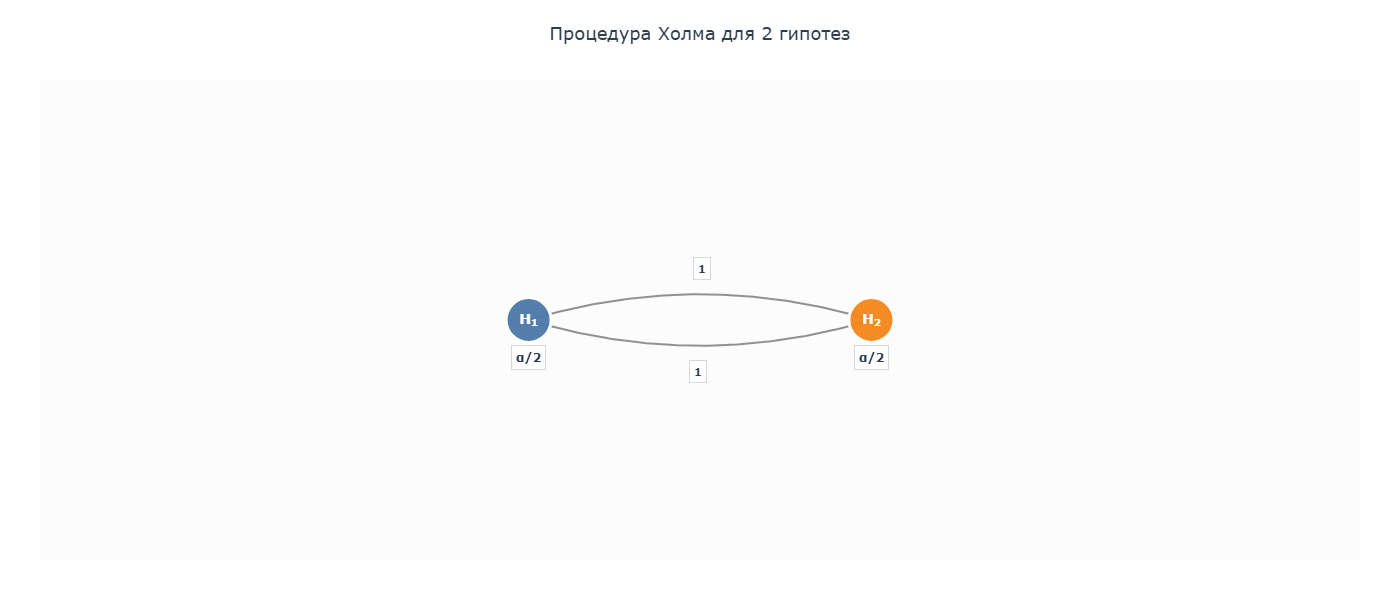

**Начальный вектор весов:** $\boldsymbol{\alpha} = (\alpha/2,\, \alpha/2)$ — бюджет разделён поровну.  
**Матрица переходов:**

$$
\mathbf{G} = \begin{pmatrix}
0 & 1 \\
1 & 0
\end{pmatrix}.
$$


**Интерпретация:**

Если отвергнута $H_1$, её уровень $\alpha/2$ полностью переходит к $H_2$ (ребро с весом 1), так что теперь $H_2$ будет проверяться на уровне $\alpha/2 + \alpha/2 = \alpha$. Если же первой будет отвергнута $H_2$, её уровень аналогично передаётся $H_1$. Таким образом, граф из двух вершин с симметричными рёбрами полностью кодирует процедуру Холма для $m = 2$. Как мы увидим далее, обобщение на $m$ гипотез потребует полносвязного графа с равными весами $g_{ij} = 1/(m-1)$, и это будет в точности процедура Холма.

### 2.2 Алгоритм последовательного тестирования

Итак, у нас есть граф, заданный начальным вектором весов $\boldsymbol{\alpha}$ и матрицей переходов $\mathbf{G}$. Теперь мы должны формально определить, как именно с его помощью проверять гипотезы. Следующий алгоритм описывает простую итеративную процедуру, которая шаг за шагом отвергает гипотезы и обновляет граф.

---

**Входные данные**

- Множество элементарных нулевых гипотез $H_1,\dots,H_m$.
- Наблюдаемые p‑значения $p_1,\dots,p_m$.
- Общий уровень значимости $\alpha \in (0,1)$.
- Начальное распределение $\boldsymbol{\alpha} = (\alpha_1,\dots,\alpha_m)$.
- Матрица переходов $\mathbf{G} = (g_{ij})$.

---

**Алгоритм**

1. **Инициализация**  
   1.1 Положим $I = \{1,\dots,m\}$ – множество индексов ещё не отвергнутых гипотез.

2. **Выбор гипотезы для проверки**  
   2.1. Вычислим для всех $i \in I$ величину $p_i / \alpha_i$.  
   2.2. Выберем индекс $j \in I$, для которого это отношение минимально
   $$
   j = \arg\min_{i \in I} \frac{p_i}{\alpha_i}
   $$

3. **Проверка и остановка**  
   3.1. Если $p_j \le \alpha_j$, то **отвергаем** $H_j$.  
   3.2. Иначе – **останавливаем всю процедуру**: оставшиеся гипотезы не отвергаются.

4. **Обновление графа после отвержения**  
   После того как $H_j$ отвергнута, мы удаляем соответствующую вершину и перераспределяем её уровень $\alpha_j$ между оставшимися гипотезами. Формально:

   - Удаляем индекс $j$ из множества $I$:  $I \leftarrow I \setminus \{j\}$.

   - Обновляем уровни значимости оставшихся гипотез:   
   $$
   \alpha_\ell \leftarrow \alpha_\ell + \alpha_j \cdot g_{j\ell}, \qquad \ell \in I \\
   \alpha_\ell \leftarrow 0 , \qquad \ell \notin I
   $$

   - Обновляем матрицу переходов:  
   $$
   g_{\ell k} \leftarrow \frac{g_{\ell k} + g_{\ell j} \cdot g_{jk}}{1 - g_{\ell j} \cdot g_{j\ell}}, \qquad \ell,k \in I,\ \ell \neq k \\
   g_{\ell k} \leftarrow 0, \qquad \ell,k \notin I,\ \ell \neq k
   $$

5. **Повторение**  
   Если после обновления в $I$ ещё остались гипотезы ($|I| \ge 1$), возвращаемся к шагу 2, иначе завершаем процедуру.

ㅤ

**Свойства алгоритма**

1. **Строгий контроль FWER.**  
   Процедура гарантирует, что вероятность хотя бы одного ложного отклонения не превышает $\alpha$ при любых конфигурациях истинных и ложных нулевых гипотез. Доказательство опирается на связь с замкнутой процедурой тестирования – мы обсудим это в разделе 2.3.

2. **Сокращённая процедура (shortcut).**  
   Алгоритм делает не более $m$ шагов и не требует явного перебора всех $2^m-1$ пересечений гипотез. Это чрезвычайно важно для практики.

3. **Независимость от порядка.**  
   Если на шаге 2 сразу несколько гипотез удовлетворяют условию $p_i \le \alpha_i$, окончательное множество отвергнутых гипотез не зависит от того, в каком порядке мы их отвергаем. Выбор «минимального отношения» – лишь удобный способ определить очерёдность.


ㅤ

**Простая иллюстрация: Холм для $m=2$**

Рассмотрим граф с $\boldsymbol{\alpha} = (\alpha/2, \alpha/2)$ и $g_{12}=g_{21}=1$. Пусть $p_1 < p_2$, и $p_1 \le \alpha/2$.

1. $p_1/\alpha_1 = \frac{p_1}{\alpha/2}$ минимально. Отвергаем $H_1$.
2. Удаляем вершину $H_1$. Уровень $\alpha/2$ полностью переходит к $H_2$:  
   $\alpha_2 \leftarrow \alpha/2 + (\alpha/2) \cdot 1 = \alpha$.
3. Теперь проверяем $H_2$: $p_2 \le \alpha$. Если да – отвергаем $H_2$, иначе – нет.

Это в точности процедура Холма: сначала проверяем более значимую гипотезу на уровне $\alpha/2$, затем оставшуюся – на полном $\alpha$.

In [9]:
# Пример использования
alpha = 0.05
m = 2

# Начальные веса: поровну
alpha_vec = np.array([alpha/m, alpha/m])

# Матрица переходов: полносвязный граф с равными весами
g_weight = 1.0 / (m - 1)
G = np.full((m, m), g_weight)
np.fill_diagonal(G, 0)

# Пример p-значений из статьи Bretz et al. (2009)
p_vals = np.array([0.02, 0.055])

graph = Graph(m, alpha, alpha_vec, p_vals, G)

In [10]:
graph.draw_initial_graph(title=f"Визуализация процедуры Холма для m={m} гипотез", width=1400, height=390,
                         show_alpha_values=True, alpha_symbol="α")

In [11]:
_ = graph.run_full_analysis(title="Полный анализ", width=1200, height=280,
                        show_alpha_values=False, alpha_symbol="α")

## 🚀 Полное тестирование с визуализацией

**Исходные p-значения:** [0.0200, 0.0550]

**Исходные локальные α:** [1/40, 1/40]

**α = 0.05**

### Шаг 1. Рассматриваемые гипотезы: $I_{0} = \{1, 2\}$

...

| Показатель | $H_{2}$ |
| --- | --- |
| $p$-значения | 0.0550 |
| Локальные $\alpha(I_{1})$ | $1/20$ |
| Веса $w_i(I_{1}) = \alpha_i(I_{1}) / \alpha$ | $1$ |

**2.** Наименьшее отношение $p/\alpha$ у гипотезы $H_{2}$: 0.0550 / 1/20 = 1.1000. $p_{2} > \alpha_{2}$ → **Гипотеза $H_{2}$ НЕ отвергается** ❌


---
### Результаты

**Отвергнутые гипотезы:** $H_{1}$

**Не отвергнутые:** $H_{2}$

### 2.3 Связь с замкнутой процедурой тестирования

Ранее мы реализовали алгоритм, который шаг за шагом отвергает гипотезы и перераспределяет уровни значимости. Теперь мы строго докажем, что этот алгоритм контролирует групповую вероятность ошибки (FWER) на заданном уровне $\alpha$. Для этого мы погрузимся в конструкцию замкнутой процедуры тестирования (closed testing procedure) и покажем, что графический подход является её эффективной реализацией.

#### 2.3.1 Замкнутая процедура тестирования

Рассмотрим множество элементарных нулевых гипотез $H_1, H_2, \ldots, H_m$. Для любого непустого подмножества индексов $I \subseteq \{1,\ldots,m\}$ определим **пересечение гипотез** $H_I = \bigcap_{i \in I} H_i$, которое утверждает, что все $H_i$ с $i \in I$ верны одновременно. Замкнутая процедура тестирования (Marcus et al., 1976) состоит из двух правил:

1. Для каждого $I \subseteq \{1,\ldots,m\}$ выбирается **локальный тест** уровня $\alpha$, который проверяет $H_I$. Локальный тест может отвергнуть $H_I$ или нет.
2. Элементарная гипотеза $H_i$ отвергается **тогда и только тогда**, когда для **всех** $I$, содержащих $i$, локальный тест отвергает $H_I$.

Процедура гарантирует сильный контроль FWER на уровне $\alpha$ при любых зависимостях между $p$-значениями, если каждый локальный тест корректен (т.е. вероятность ошибочно отвергнуть истинное пересечение не превышает $\alpha$). Доказательство чрезвычайно просто и изящно.

ㅤ

**Теорема (контроль FWER замкнутой процедурой).**  
Пусть $T \subseteq \{1,\ldots,m\}$ — множество индексов истинных нулевых гипотез. Тогда FWER — это вероятность отвергнуть хотя бы одну $H_i$ с $i \in T$.

По построению, чтобы отвергнуть такую $H_i$, необходимо отвергнуть пересечение $H_T$ (так как $T$ содержит $i$, и условие требует отвержения всех пересечений, содержащих $i$). Следовательно, $\text{FWER} \le P$(локальный тест отвергает $H_T).$ Но $H_T$ — истинное пересечение (все гипотезы в $T$ верны), поэтому вероятность его ошибочного отвержения не превышает $\alpha$ по определению локального теста. Отсюда $\text{FWER} \le \alpha$.

В качестве примера рассмотрим случай с 4 гипотезами. Предположим, что подчеркнутые гипотезы были отклонены локальными тестами.


$$
\underline{H_{1234}} \\
\underline{H_{123}} ㅤ \underline{H_{124}} ㅤ \underline{H_{134}} ㅤ \underline{H_{234}} \\
\underline{H_{12}} ㅤ \underline{H_{13}} ㅤ \underline{H_{14}} ㅤ \underline{H_{23}} ㅤ H_{24} ㅤ H_{34} \\
\underline{H_1} ㅤ \underline{H_2} ㅤ H_3 ㅤ H_4
$$

* Здесь $H_1$ и $H_{23}$ отклонены закрытой процедурой тестирования.
* $H_2$ не отклоняется в ходе закрытого тестирования, так как $H_{24}$ не отклоняется в ходе локального тестирования.

ㅤ

К сожалению, наивная реализация требует провести $2^m - 1$ локальных тестов — уже при $m = 10$ это 1023 теста. Чтобы сделать процедуру практически применимой, необходимо строить локальные тесты специального вида, допускающие **сокращённую процедуру (shortcut)**, которая эквивалентна полному замкнутому тесту, но выполняет не более $m$ шагов.

#### 2.3.2 Взвешенный тест Бонферрони как локальный тест

В графическом подходе для каждого $I \subseteq M$ используется взвешенный тест Бонферрони. Для $I$ задаются неотрицательные веса $w_i(I)$, $i \in I$, такие что $\sum_{i \in I} w_i(I) \le 1$. Тогда пересечение $H_I$ отвергается, если существует $i \in I$, для которого $p_i \le w_i(I) \cdot \alpha$. Такой тест имеет уровень $\alpha$ благодаря неравенству Бонферрони:

$$
P_{H_I}\left( \bigcup_{i \in I} \{ p_i \le w_i(I)\alpha \} \right) \le \sum_{i \in I} P_{H_I}(p_i \le w_i(I)\alpha) \le \sum_{i \in I} w_i(I)\alpha \le \alpha.
$$

Таким образом, локальный тест корректен для любого $I$.

ㅤ

**Построение весов из графа**

Начальный граф $(\alpha, G)$ неявно задаёт семейство весов $\{w_i(I)\}$ для всех $I \subseteq M$. Алгоритм, представленный ранее, строит эти веса последовательным удалением вершин, не входящих в $I$.

Формально, пусть $J = M \setminus I$ — множество индексов, подлежащих удалению. Начиная с исходного вектора $\alpha(M) = \alpha$ и матрицы $G(M) = G$, мы поочерёдно удаляем индексы $j \in J$, применяя правила обновления:

$$
\alpha_\ell(J) =
\begin{cases}
\alpha_\ell(I) + \alpha_j(I)\, g_{j\ell}(I), & \ell \in J, \\
0, & \text{иначе},
\end{cases}
$$

$$
g_{\ell k}(J) =
\frac{g_{\ell k}(I) + g_{\ell j}(I)\, g_{jk}(I)}{1 - g_{\ell j}(I)\, g_{j\ell}(I)}, \quad \ell,k \in J,\ \ell \neq k, \text{ где } I = J \cup \{j\}
$$

В статье доказано, что итоговые веса $\alpha_i(J)$ не зависят от порядка удаления индексов. Полагая, что $w_i(I) = \alpha_i(I)/\alpha$, по построению получаем, что $\sum_{i \in I} w_i(I) \le 1$.


#### 2.3.3 Построение shortcut-а замкнутой процедуры

**Условие монотонности**

Ключевое свойство, обеспечивающее существование shortcut, — **монотонность** весов:

$$w_i(J) \ge w_i(I) \quad \text{для всех } J \subseteq I,\ i \in J.$$

В терминах исходных $\alpha_i(I)$ это означает, что при удалении гипотез (переходе от большего пересечения к меньшему) оставшиеся гипотезы могут только увеличить свою долю уровня значимости. В той же статье строго доказано, что веса, порождённые алгоритмом, предстаавленном выше, удовлетворяют условию монотонности. Интуитивно это ясно: удаляя гипотезу, мы перераспределяем её уровень на оставшиеся, поэтому их веса не уменьшаются.

**Консонантность и сокращённая процедура**

Замкнутая процедура называется **консонантной**, если для любого пересечения $H_I$, которое отвергается локальным тестом, существует хотя бы одна элементарная гипотеза $H_i$ ($i \in I$), которая может быть отвергнута на том же уровне значимости при проверке **только этого пересечения**. Иными словами, отвержение пересечения немедленно влечёт возможность отвергнуть какую-то индивидуальную гипотезу из этого пересечения.

Формально, пусть $I \subseteq \{1,\dots,m\}$ и локальный тест отвергает $H_I$. Тогда существует $i \in I$, для которого $p_i \leq \alpha_i(I),$ где $\alpha_i(I) = w_i(I)\,\alpha$ – локальный уровень, выделенный гипотезе $H_i$ внутри пересечения $I$.

ㅤ

Замкнутая процедура с взвешенными бонферрониевскими тестами, обладающими монотонностью, является **консонантной**. Чтобы понять это, рассмотрим локальный тест для $H_I$: она будет отвергнута, если  $\min_{i\in I} \left( p_i \leq w_i(I) \cdot \alpha \right) $ ~ $\min_{i\in I} \left( \frac{p_i}{w_i(I)} \leq \alpha \right) $. Выберем индекс $j \in I$, на котором достигается минимум. Тогда $\frac{p_j}{w_j(I)} \leq \alpha \quad \Rightarrow \quad p_j \leq w_j(I)\,\alpha = \alpha_j(I).$

Следовательно, элементарная гипотеза $H_j$ может быть отвергнута при проверке одного лишь пересечения $H_I$. Таким образом, консонантность выполняется **автоматически** для любого взвешенного теста Бонферрони. Ключевым является то, что **монотонность весов** обеспечивает, что после удаления отвергнутой гипотезы оставшиеся сохранят (или увеличат) свои веса, и процедура может продолжаться без нарушения контроля FWER.

**От консонантности к сокращённой процедуре**

Представим, что мы применяем замкнутую процедуру наивно: перебираем все $I \subseteq M$ в порядке возрастания размера, проверяем, отвергается ли $H_I$ по Бонферрони, и затем формируем множество отвергнутых элементарных гипотез согласно правилу: $H_i$ отвергается, если **для всех** $I$, содержащих $i$, $H_I$ отвергнуто.

Консонантность позволяет заменить эту экспоненциальную проверку последовательным алгоритмом, работающим **только с текущим множеством ещё не отвергнутых гипотез**. Вот логика shortcut:

1. В начальный момент у нас есть всё множество $M$ и веса $w_i(M)$. Поскольку пересечение $H_M$ соответствует проверке сразу всех гипотез, его локальный тест – это обычный взвешенный Бонферрони. Отвергаем $H_j$, если $p_j \leq w_j(M)\,\alpha$.
2. Если такая $H_j$ найдена, то **консонантность гарантирует**, что для любого другого пересечения $I$, содержащего $j$, также найдётся отвержение (поскольку удаление других гипотез может только увеличить вес $j$). Следовательно, $H_j$ будет отвергнута и в полной замкнутой процедуре.
3. Мы удаляем $H_j$ из рассмотрения и переходим к множеству $M' = M \setminus \{j\}$. Для этого множества мы **заново вычисляем веса** $w_i(M')$ по тем же правилам, что и в Алгоритме A1. Монотонность гарантирует, что для всех оставшихся $i$ выполняется $w_i(M') \geq w_i(M)$. Теперь мы снова применяем взвешенный Бонферрони к $H_{M'}$ – и так до тех пор, пока на очередном шаге ни одна гипотеза не будет отвергнута.
4. Процедура останавливается, когда $\min_{i\in I} \left( p_i/\alpha_i(I) > 1 \right)$. Все гипотезы, отвергнутые на предыдущих шагах, считаются отвергнутыми.

Эта последовательная процедура, как доказано в Hommel, Bretz & Maurer (2007), **эквивалентна полной замкнутой процедуре** и, следовательно, контролирует FWER. При этом она требует не более $m$ шагов и избавляет от необходимости явно выписывать и проверять $2^m-1$ пересечений.

ㅤ

Теперь видно, что алгоритм, представленный до этого, есть не что иное, как этот shortcut:

- **Шаг 2** (выбор $j$ с минимальным $p_i/\alpha_i$) – ровно то же самое, что поиск индекса, доставляющего минимум в локальном тесте Бонферрони для текущего пересечения $H_I$.
- **Шаг 3** (проверка $p_j \leq \alpha_j$) – отвержение $H_j$ на уровне $\alpha_j(I)$, что в силу консонантности означает отвержение $H_j$ в замкнутой процедуре.
- **Шаг 4** (обновление графа) – пересчёт весов для нового множества $I \setminus \{j\}$.

Таким образом, предлагаемый алгоритм напрямую реализует замкнутую процедуру тестирования с взвешенными бонферрониевскими тестами, гарантируя строгий контроль FWER без каких-либо дополнительных предположений о структуре зависимости $p$-значений.

#### 2.3.4 Пример

Пусть
* $m = 4$
* общий уровень $\alpha = 0.05$
* $\alpha = (0.01,\; 0.02,\; 0.01,\; 0.01)$
* $p$-значения $= (0.008,\; 0.03,\; 0.009,\; 0.10)$

* Матрица переходов $G$:

$$
\mathbf{G} = \begin{pmatrix}
0 & 0.5 & 0.5 & 0\\
0 & 0 & 0 & 1\\
0 & 0 & 0 & 1\\
0 & 0 & 0 & 0
\end{pmatrix}
$$

___


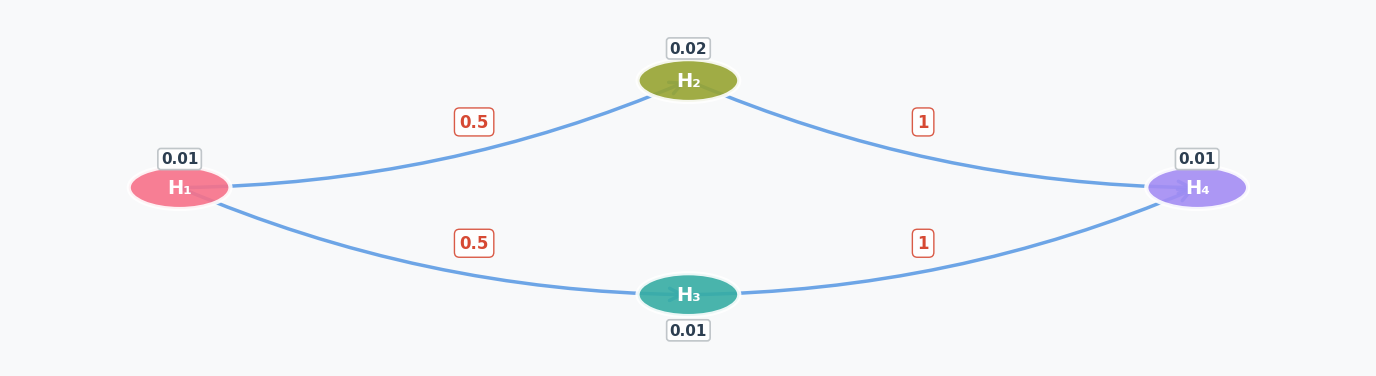

**Шаг 0. Исходное пересечение $H_{\{1,2,3,4\}}$**

* Считаем веса для $I_0 = \{1,2,3,4\}$: $w_i = \alpha_i / \alpha = (0.01/0.05,\; 0.02/0.05,\; 0.01/0.05,\; 0.01/0.05) = (0.2,\;0.4,\;0.2,\;0.2)$.

* Локальный взвешенный тест Бонферрони для $H_{I_0}$:
  * вычисляем для каждой гипотезы значение $p_i / \alpha_i$

  $$
  \frac{0.008}{0.01}=0.8,\quad
  \frac{0.03}{0.02}=1.5,\quad
  \frac{0.009}{0.01}=0.9,\quad
  \frac{0.10}{0.01}=10.
  $$
    
  * Условие отвержения пересечения: $\min_i p_i/w_i \le \alpha$ ~ $\min_i p_i / \alpha_i \le 1$.
  
    У $H_1$ минимальный коэффициент ($0.8$), и т.к. $0.8 \le 1$, то пересечение $H_{\{1,2,3,4\}}$ **отвергается**.  
* По свойству консонантности $H_1$ может быть отвергнута на уровне $\alpha_1(I_0)=0.01$, ведь $p_1 \le w_1(I_0) \cdot \alpha ㅤ(0.008 \le 0.02 \cdot 0.05)$.

**Итог шага:** отвергаем $H_1$, удаляем её из множества и идём на следующую итерацию.

**Шаг 1. Удаляем $H_1$, обновляем веса для $I_1 = \{2,3,4\}$**

Перераспределяем $\alpha_1=0.01$ согласно $G$ ($g_{12}=0.5$, $g_{13}=0.5$):
- $\alpha_2^{\text{new}} = 0.02 + 0.01\cdot 0.5 = 0.025$
- $\alpha_3^{\text{new}} = 0.01 + 0.01\cdot 0.5 = 0.015$
- $\alpha_4^{\text{new}} = 0.01$ (без изменений, т.к. из $H_1$ нет перехода в $H_4$)

ㅤ

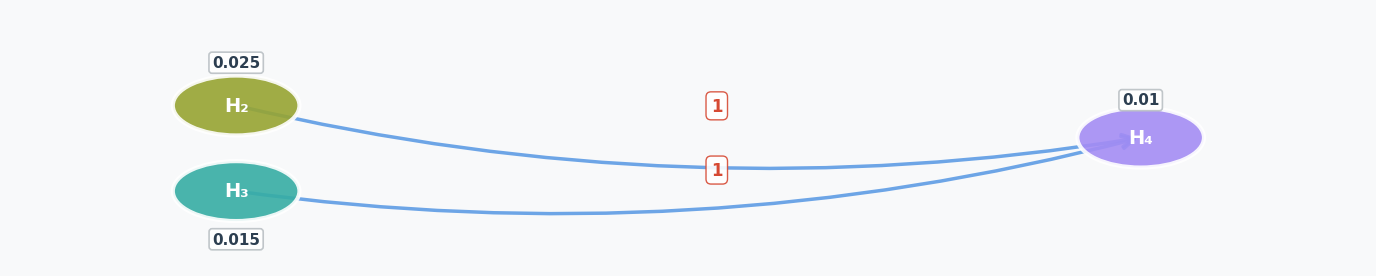

**Шаг 2. Тестируем пересечение  H{2,3,4}**

* Считаем новые веса для $I_1$: $w_i(I_1) = \alpha_i^{\text{new}} / \alpha$: $(0.025/0.05=0.5,\; 0.015/0.05=0.3,\; 0.01/0.05=0.2)$.


* Локальный взвешенный тест Бонферрони для $H_{I_1}$:
  * вычисляем для каждой гипотезы значение $p_i / \alpha_i$

  $$
  \frac{p_2}{\alpha_2^{\text{new}}} = \frac{0.03}{0.025}=1.2,\quad
  \frac{p_3}{\alpha_3^{\text{new}}} = \frac{0.009}{0.015}=0.6,\quad
  \frac{p_4}{\alpha_4^{\text{new}}} = \frac{0.10}{0.01}=10.
  $$
    
  * Условие отвержения пересечения: $\min_i p_i/w_i \le \alpha$ ~ $\min_i p_i / \alpha_i \le 1$.
  
    У $H_3$ минимальный коэффициент ($0.6$), и т.к. $0.6 \le 1$, то пересечение $H_{\{2,3,4\}}$ **отвергается**.  
* По свойству консонантности $H_3$ может быть отвергнута на уровне $\alpha_3(I_1)=0.015$, ведь $p_3 \le w_3(I_1) \cdot \alpha ㅤ(0.009 \le 0.3 \cdot 0.05)$.

**Итог шага:** отвергаем $H_3$, удаляем её из множества и идём на следующую итерацию.

**Шаг 3. Удаляем $H_3$, обновляем веса для $I_2 = \{2,4\}$**

Из $H_3$ был переход $g_{34}=1.0$, поэтому вес $H_3$ ($0.015$) целиком переходит к $H_4$:
- $\alpha_2$ остаётся $0.025$ (нет переходов из $H_3$ в $H_2$)
- $\alpha_4^{\text{new}} = 0.01$ $+ 0.015\cdot 1.0 = 0.025$

ㅤ

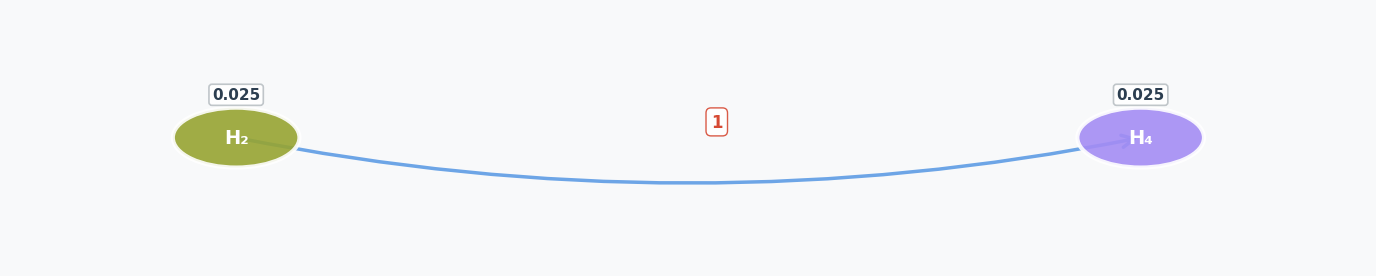

**Шаг 4. Тестируем пересечение  H{2,4}**

* Считаем новые веса для $I_2$: $w_i(I_2) = \alpha_i^{\text{new}} / \alpha$: $(0.025/0.05=0.5,\; 0.025/0.05=0.5)$.


* Локальный взвешенный тест Бонферрони для $H_{I_2}$:
  * вычисляем для каждой гипотезы значение $p_i / \alpha_i$

  $$
  \frac{p_2}{\alpha_2} = \frac{0.03}{0.025}=1.2,\quad
  \frac{p_4}{\alpha_4} = \frac{0.10}{0.025}=4.0.
  $$
    
  * Условие отвержения пересечения: $\min_i p_i/w_i \le \alpha$ ~ $\min_i p_i / \alpha_i \le 1$.
  
    У $H_2$ минимальный коэффициент ($1.2$), и т.к. $1.2 \ge 1$, то пересечение $H_{\{2,4\}}$ **не отвергается**.  

**Итог шага:** Процедура останавливается.

**Итог**

| Шаг | Рассматриваемое множество $I$ | Отвергается? | Какая $H_i$ отвергается (минимум $p_i/\alpha_i$) |
|-----|-------------------------------|--------------|------------------------------------------------|
| 0   | $\{1,2,3,4\}$                 | Да ($0.8\le1$) | $H_1$ ($p_1/\alpha_1=0.8$)                    |
| 1   | $\{2,3,4\}$                   | Да ($0.6\le1$) | $H_3$ ($p_3/\alpha_3=0.6$)                    |
| 2   | $\{2,4\}$                     | Нет ($1.2>1$) | –                                              |

**Проверка замкнутой процедурой**

Полная замкнутая процедура должна проверить все $2^4-1=15$ пересечений. Мы не делаем этого явно, но проверим, что $H_1$ и $H_3$ действительно отвергаются по правилу "отвергается, если все содержащие её пересечения отвергнуты".

- **Для $H_1$**: нужно проверить все $I$, содержащие $1$. Возьмём, например, $I=\{1,2,4\}$. Веса для такого пересечения (удаляем $H_3$) пересчитываются по тому же алгоритму. Можно показать, что для любого $I$ с $1 \in I$ локальный тест отвергает $H_I$, потому что $p_1=0.008$ очень мало и веса $w_1(I)$ только растут при удалении других гипотез (монотонность). Минимум всегда будет достигаться на $H_1$ или на другой отвергнутой гипотезе. Аналогично для $H_3$.

- **Для $H_2$**: существует пересечение $I=\{2,4\}$, которое не отвергнуто → $H_2$ не отвергается.
- **Для $H_4$**: пересечение $\{4\}$ (сама $H_4$) проверяется отдельно: при $I=\{4\}$ вес $w_4=1$, условие $p_4 \le \alpha$ не выполнено ($0.10 > 0.05$), так что $H_4$ не отвергается.

Таким образом, shortcut дал тот же результат, что и полная замкнутая процедура, но за 2 итерации вместо 15 проверок.

## 3. Детальный разбор ключевых примеров

Теперь, вооружённые полным пониманием алгоритма и его теоретической базы, перейдём к конкретным примерам. Начнём с самого простого, чтобы убедиться: классическая поправка Бонферрони – это частный случай графического подхода.

### 3.1 Пример 0: поправка Бонферрони как вырожденный граф

**Построение графа**

Пусть у нас $m$ элементарных гипотез $H_1,\dots,H_m$.
* Назначим начальные веса **поровну**: $\alpha_i = \frac{\alpha}{m}, \qquad i=1,\dots,m.$ Очевидно, $\sum_i \alpha_i = \alpha$.

* Зададим матрицу переходов $\mathbf{G}$: $g_{ij} = 0 \quad \text{для всех } i,j.$ Это означает, что из каждой вершины не исходит ни одного ребра – граф представляет собой $m$ изолированных узлов. Сумма весов исходящих рёбер равна $0 \le 1$, условие регулярности выполнено.

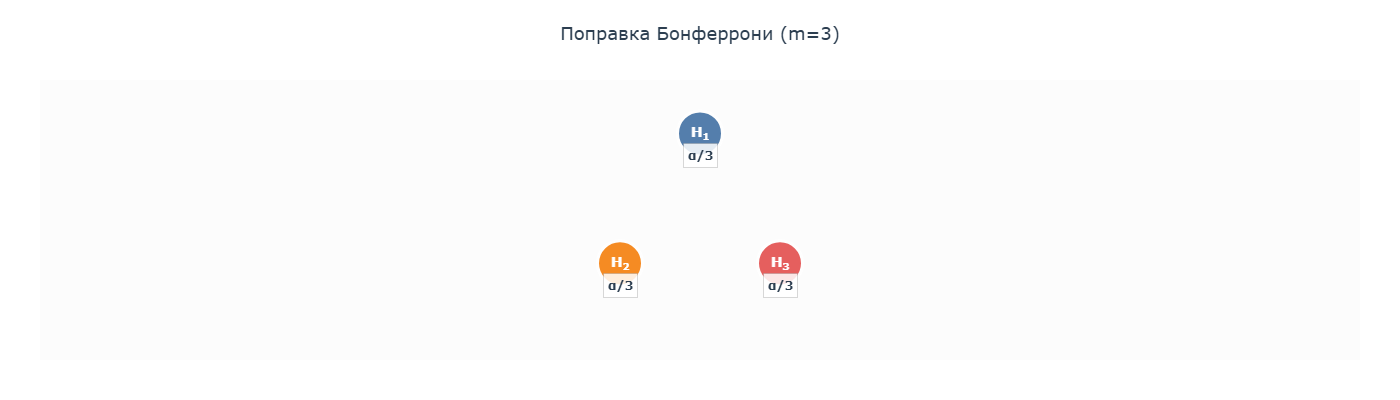

ㅤ

**Применение Алгоритма**

Запустим на таком графе Алгоритм с наблюдаемыми p‑значениями $p_1,\dots,p_m$.

1. **Инициализация:** $I = \{1,\dots,m\}$, $\alpha_i = \alpha/m$ для всех $i\in I$.
2. **Выбор гипотезы:** находим $j$ с наименьшим отношением $p_i / \alpha_i$. Поскольку все $\alpha_i$ одинаковы, это эквивалентно выбору гипотезы с **наименьшим p‑значением**.
3. **Проверка:** если $p_j \le \alpha_j = \alpha/m$, отвергаем $H_j$; иначе **стоп**.
4. **Обновление графа после отвержения $H_j$:**
   - Удаляем $j$ из $I$.
   - Для всех $\ell \in I$:
  $$
  \alpha_\ell \leftarrow \alpha_\ell + \alpha_j \cdot g_{j\ell} = \alpha_\ell + \alpha_j \cdot 0 = \alpha_\ell.
  $$
     Уровни оставшихся гипотез **не меняются**.
   - Матрица переходов остаётся нулевой.
5. **Повтор:** возвращаемся к шагу 2 с тем же набором $\alpha_i = \alpha/m$, но с уменьшенным множеством $I$. На следующей итерации снова будет выбрана гипотеза с минимальным $p$ среди оставшихся, и она будет проверена на том же уровне $\alpha/m$.

Таким образом, процедура последовательно перебирает гипотезы в порядке возрастания p‑значений и отвергает их до тех пор, пока очередное p‑значение не превысит **один и тот же порог** $\alpha/m$. Это в точности **поправка Бонферрони**: отвергаются все гипотезы с $p_i \le \alpha/m$.


При этом, в отличие от других процедур, уровень значимости не перераспределяется – каждое сравнение происходит на изначально выделенном кусочке $\alpha/m$, а освободившийся - сгорает, и именно поэтому поправка Бонферрони является самой консервативной.

In [13]:
# Пример использования
alpha = 0.05
m = 3

# Начальные веса: поровну
alpha_vec = np.array([alpha/m, alpha/m, alpha/m])

# Матрица переходов: полносвязный граф с равными весами
g_weight = 0
G = np.full((m, m), g_weight)
np.fill_diagonal(G, 0)

# Пример p-значений из статьи Bretz et al. (2009)
p_vals = np.array([0.02, 0.055, 0.012])

graph = Graph(m, alpha, alpha_vec, p_vals, G)

In [15]:
graph.draw_initial_graph(title="Визуализация процедуры Бонферрони для m=3 гипотез", width=1400, height=490,
                         show_alpha_values=True, alpha_symbol="α")

In [16]:
_ = graph.run_full_analysis(title="Полный анализ", width=1200, height=270,
                        show_alpha_values=False, alpha_symbol="α")

## 🚀 Полное тестирование с визуализацией

**Исходные p-значения:** [0.0200, 0.0550, 0.0120]

**Исходные локальные α:** [1/60, 1/60, 1/60]

**α = 0.05**

### Шаг 1. Рассматриваемые гипотезы: $I_{0} = \{1, 2, 3\}$

...

| Показатель | $H_{1}$ | $H_{2}$ |
| --- | --- | --- |
| $p$-значения | 0.0200 | 0.0550 |
| Локальные $\alpha(I_{1})$ | $1/60$ | $1/60$ |
| Веса $w_i(I_{1}) = \alpha_i(I_{1}) / \alpha$ | $1/3$ | $1/3$ |

**2.** Наименьшее отношение $p/\alpha$ у гипотезы $H_{1}$: 0.0200 / 1/60 = 1.2000. $p_{1} > \alpha_{1}$ → **Гипотеза $H_{1}$ НЕ отвергается** ❌


---
### Результаты

**Отвергнутые гипотезы:** $H_{3}$

**Не отвергнутые:** $H_{1}$, $H_{2}$

### 3.2 Пример 1: процедура Холма как граф

**Построение графа**

Пусть у нас $m$ элементарных гипотез $H_1,\dots,H_m$.
* Назначим начальные веса **поровну**: $\alpha_i = \frac{\alpha}{m}, \qquad i=1,\dots,m.$ Очевидно, $\sum_i \alpha_i = \alpha$.

* Зададим матрицу переходов $\mathbf{G}$: $g_{ij} = \frac{1}{m-1}\;, g_{ii} = 0$. Сумма весов исходящих рёбер равна $\sum_{j=1}^m g_{ij} = (m-1)\cdot\frac{1}{m-1} = 1$, условие регулярности выполнено.

ㅤ

Таким образом, получается **полносвязный ориентированный граф**, в котором от каждой вершины к каждой другой идёт ребро с весом $1/(m-1)$.

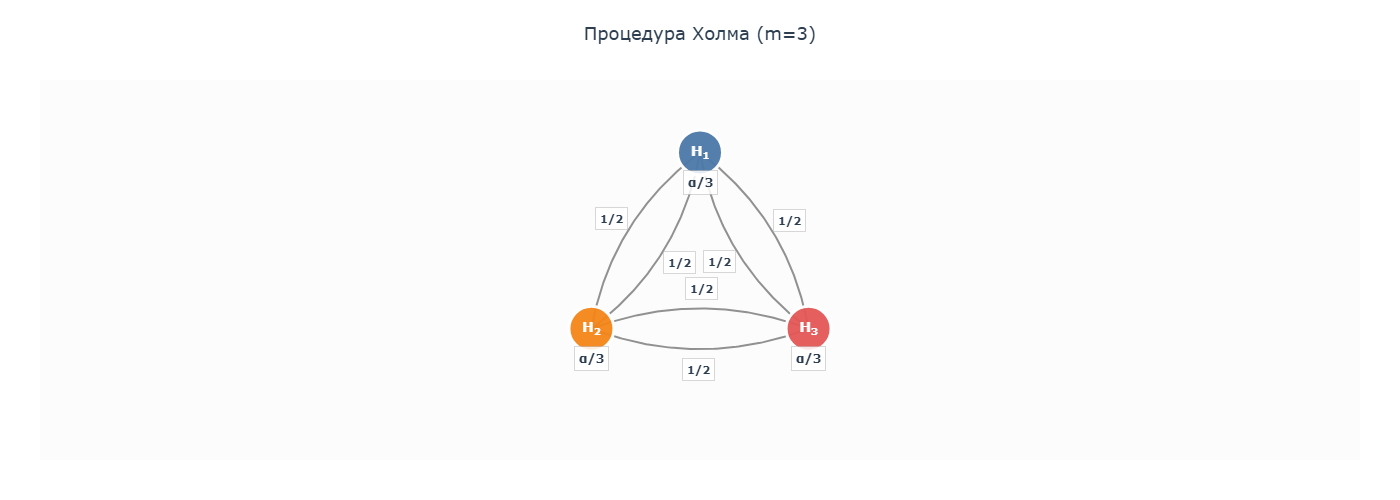

**Классическая процедура Холма**

Прежде чем запускать алгоритм, вспомним стандартную формулировку Холма:

1. Упорядочить p‑значения: $p_{(1)} \le p_{(2)} \le \dots \le p_{(m)}$ с соответствующими гипотезами $H_{(1)},\dots,H_{(m)}$.
2. Найти наименьший индекс $i$, для которого $p_{(i)} > \frac{\alpha}{m-i+1}$.
3. Отвергнуть все гипотезы $H_{(1)},\dots,H_{(i-1)}$.

Иными словами, самая значимая гипотеза тестируется на уровне $\alpha/m$, следующая — на $\alpha/(m-1)$, и т.д. Как только встречается гипотеза, не преодолевающая свой барьер, процедура останавливается.

ㅤ

**Работа Алгоритма на графе Холма**

Покажем, что применение Алгоритма к построенному графу даёт в точности те же результаты. Возьмём $m=3$, $\alpha=0.05$ и p‑значения $= (0.02, 0.055, 0.012)$

**Шаг 1.** Инициализация: $I = \{1,2,3\}$

  * $\alpha_i = \alpha/3 \approx 0.0167$

  * Вычисляем отношения:

  $$
  \frac{p_1}{\alpha_1} = \frac{0.02}{0.0167} \approx 1.20\qquad
  \frac{p_2}{\alpha_2} = \frac{0.055}{0.0167} \approx 3.30\qquad
  \frac{p_3}{\alpha_3} = \frac{0.012}{0.0167} \approx 0.72
  $$

  * Минимальное отношение у $H_3$: $p_3 = 0.012 \le 0.0167$ — **отвергаем и удаляем из графа $H_3$**

  * $\alpha/3$ перераспределяется поровну между $H_1$ и $H_2$ (потому что $g_{31} = g_{32} = 1/2$):

$$
\alpha_1 \leftarrow \frac{\alpha}{3} + \frac{\alpha}{3}\cdot\frac{1}{2} = \frac{\alpha}{2} = 0.025
$$
$$
\alpha_2 \leftarrow \frac{\alpha}{3} + \frac{\alpha}{3}\cdot\frac{1}{2} = \frac{\alpha}{2} = 0.025
$$

  * Пересчитывается $G$: $g_{12} = g_{21} = 1$

**Шаг 2.** Инициализация: $I = \{1,2\}$

  * $\alpha_1=\alpha_2=0.025$. Отношения:

  * Вычисляем отношения:
$$
\frac{p_1}{\alpha_1} = \frac{0.02}{0.025} = 0.8 \qquad
\frac{p_2}{\alpha_2} = \frac{0.055}{0.025} = 2.2
$$

  * Минимальное у $H_1$: $p_1 = 0.02 \le 0.025$ — **отвергаем и удаляем из графа $H_1$**.

  * $\alpha/2$ переходит к $H_2$. Получаем $\alpha_2 = 0.025 + 0.025 = 0.05$.

**Шаг 3.** Осталась одна $H_2$, проверяем: $p_2 = 0.055 > 0.05$ — **не отвергаем**.

**Итого**

Отвергнуты $H_3$ и $H_1$ — ровно те гипотезы, которые были бы отвергнуты классической процедурой Холма (на первом шаге $p_{(1)}=0.012 \le 0.05/3$, на втором $p_{(2)}=0.02 \le 0.05/2$, на третьем $p_{(3)}=0.055 > 0.05/1$).


ㅤ

**Почему граф с равными весами даёт процедуру Холма?**

Секрет кроется в том, что на каждом шаге после удаления $k$ гипотез веса оставшихся становятся одинаковыми и равными $\alpha/(m-k)$. Действительно, полносвязный граф с равными переходами $1/(m-1)$ обладает свойством «забывания»: откуда бы ни пришёл уровень значимости, он всегда равномерно распределяется между всеми оставшимися вершинами. В результате на $k$-м шаге каждая из $m-k+1$ оставшихся гипотез имеет локальный уровень $\alpha/(m-k+1)$, что в точности совпадает с порогами Холма.

In [18]:
# Пример использования
alpha = 0.05
m = 3

# Начальные веса: поровну
alpha_vec = np.array([alpha/m, alpha/m, alpha/m])

# Матрица переходов: полносвязный граф с равными весами
g_weight = 1.0 / (m - 1)
G = np.full((m, m), g_weight)
np.fill_diagonal(G, 0)

# Пример p-значений из статьи Bretz et al. (2009)
p_vals = np.array([0.02, 0.055, 0.012])

graph = Graph(m, alpha, alpha_vec, p_vals, G)

In [19]:
graph.draw_initial_graph(title="Визуализация процедуры Холма для m=3 гипотез", width=1400, height=490,
                         show_alpha_values=True, alpha_symbol="α")

In [20]:
_ = graph.run_full_analysis(title="Полный анализ", width=1200, height=270,
                        show_alpha_values=False, alpha_symbol="α")

## 🚀 Полное тестирование с визуализацией

**Исходные p-значения:** [0.0200, 0.0550, 0.0120]

**Исходные локальные α:** [1/60, 1/60, 1/60]

**α = 0.05**

### Шаг 1. Рассматриваемые гипотезы: $I_{0} = \{1, 2, 3\}$

...

| Показатель | $H_{2}$ |
| --- | --- |
| $p$-значения | 0.0550 |
| Локальные $\alpha(I_{2})$ | $1/20$ |
| Веса $w_i(I_{2}) = \alpha_i(I_{2}) / \alpha$ | $1$ |

**2.** Наименьшее отношение $p/\alpha$ у гипотезы $H_{2}$: 0.0550 / 1/20 = 1.1000. $p_{2} > \alpha_{2}$ → **Гипотеза $H_{2}$ НЕ отвергается** ❌


---
### Результаты

**Отвергнутые гипотезы:** $H_{1}$, $H_{3}$

**Не отвергнутые:** $H_{2}$

### 3.3 Пример 2: gatekeeping процедура для двух семейств

Теперь мы переходим к одному из наиболее важных приложений графического подхода — **гейткипингу** (gatekeeping). Этот метод незаменим, когда гипотезы естественно группируются в первичные и вторичные семейства, и вторичные разрешается проверять только после успеха первичных.

ㅤ

**Мотивация: зачем нужен гейткипинг?**

Представьте типичный A/B‑тест в продукте: вы тестируете новый алгоритм рекомендаций. У вас есть **основная метрика** — средний чек на пользователя, и несколько **охранных метрик** — CTR главной страницы, удержание через неделю, время до первого заказа. Бизнес‑логика требует:

1. Сначала доказать, что новая рекомендательная система **увеличивает** revenue по сравнению с контролем.
2. Только после этого проверить, что она **не ухудшает** охранные метрики.

Если средний чек не показал значимого прироста, мы вообще не хотим тратить статистический бюджет на проверку охранных метрик — такой вариант всё равно не пойдёт в прод. Но если метрика значимо выросла, мы готовы проверить безопасность, и здесь нам нужно иметь достаточный уровень значимости для этих вторичных тестов.

Аналогичная ситуация возникает в клинических испытаниях: первичные конечные точки (например, выживаемость) должны быть доказаны до того, как переходить к анализу вторичных (качество жизни, биомаркеры). Регуляторы требуют, чтобы FWER строго контролировался на уровне $\alpha$ для **всего** исследования, включая обе группы гипотез.

Классический гейткипинг формализует эту логику: первичное семейство $\mathcal{F}_1 = \{H_1, H_2\}$ получает весь уровень $\alpha$, а вторичное семейство $\mathcal{F}_2 = \{H_3, H_4\}$ изначально имеет нулевые уровни. Уровень переходит от первичных гипотез к вторичным **только после того, как соответствующие первичные гипотезы отвергнуты**. Более того, полный переход уровня во вторичное семейство происходит лишь при условии, что **все** гипотезы первичного семейства отвергнуты (в нашем случае — обе $H_1$ и $H_2$).

**Построение графа**

Пусть у нас $m=4$ элементарных гипотез $H_1,\dots,H_4$
* Назначим начальные веса: $\boldsymbol{\alpha} = \left( \frac{\alpha}{2},\ \frac{\alpha}{2},\ 0,\ 0 \right)$

* Зададим матрицу переходов $\mathbf{G}$:
$$
\mathbf{G} = \begin{pmatrix}
0 & 0 & 1/2 & 1/2 \\
0 & 0 & 1/2 & 1/2 \\
0 & 0 & 0 & 1 \\
0 & 0 & 1 & 0
\end{pmatrix}
$$

  Матрица переходов $\mathbf{G}$ отражает правило: после отвержения первичной гипотезы её уровень делится поровну между двумя вторичными. А после отвержения вторичной — полностью передаётся другой вторичной. Рёбер между первичными и от вторичных к первичным нет:

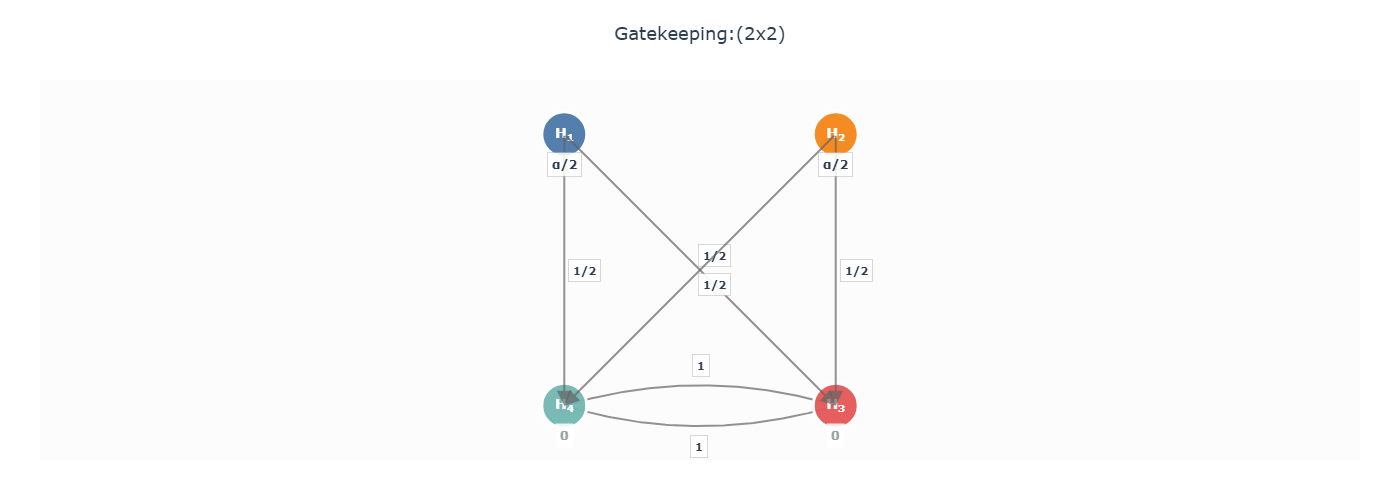

**Пример**

Пусть $\alpha=0.05$  и $p$‑значения $=(0.02,0.04,0.01,0.015)$



**Шаг 1.** Инициализация: $I = \{1,2,3,4\}$
* Локальные уровни: $\alpha_1=\alpha_2=0.025$, $\alpha_3=\alpha_4=0$  
* Сравниваем $p_i/\alpha_i$: для $H_3, H_4$ деление на ноль, поэтому они не выбираются. Выбираем минимум среди $(H_1, H_2)$:
$$
\frac{p_1}{\alpha_1} = \frac{0.02}{0.025} = 0.8 \qquad
\frac{p_2}{\alpha_2} = \frac{0.04}{0.025} = 1.6
$$

* Минимальное отношение у  $H_1$. $p_1 = 0.02 \le 0.025$ — **отвергаем и удаляем из графа $H_1$**

* Уровень $\alpha_1 = \alpha/2 = 0.025$ распределяется поровну между $H_3$ и $H_4$ (веса $g_{13}=g_{14}=1/2$):

$$
\alpha_2 \leftarrow \alpha_2 = 0.025
$$
$$
\alpha_3 \leftarrow \alpha_3 + \alpha_1 \cdot g_{13} = 0 + 0.025 \cdot \frac{1}{2} = 0.0125
$$
$$
\alpha_4 \leftarrow \alpha_4 + \alpha_1 \cdot g_{14} = 0 + 0.025 \cdot \frac{1}{2} = 0.0125
$$


**Шаг 2.** Инициализация: $I = \{2,3,4\}$.  
  * Локальные уровни: $\alpha_2 = 0.025$, $\alpha_3 = 0.0125$, $\alpha_4 = 0.0125$

  * Вычисляем отношения:
$$
\frac{p_2}{\alpha_2} = \frac{0.04}{0.025} = 1.6,\quad
\frac{p_3}{\alpha_3} = \frac{0.01}{0.0125} = 0.8,\quad
\frac{p_4}{\alpha_4} = \frac{0.015}{0.0125} = 1.2.
$$
  * Минимальное у $H_3$: $p_3 = 0.01 \le 0.0125$ — **отвергаем и удаляем из графа $H_3$**


* Уровень $\alpha_3 = 0.0125$ распределяется поровну между $H_4$:

$$
\alpha_2 \leftarrow \alpha_2 = 0.025 \quad
$$
$$
\alpha_4 \leftarrow \alpha_4 + \alpha_3 \cdot g_{34} = 0.0125 + 0.0125 \cdot 1 = 0.025.
$$


**Шаг 3.**   Инициализация: $I = \{2,4\}$.  

  * Локальные уровни: $\alpha_2 = 0.025$, $\alpha_4 = 0.025$
  * Вычисляем отношения:
$$
\frac{p_2}{\alpha_2} = \frac{0.04}{0.025} = 1.6,\qquad
\frac{p_4}{\alpha_4} = \frac{0.015}{0.025} = 0.6.
$$
  * Минимум у $H_4$: $p_4 = 0.015 \le 0.025$ — **отвергаем и удаляем из графа $H_4$**

  * Уровень $\alpha_4 = 0.025$ **теряется**, т.к. не осталось никаких гипотез из $I $, куда бы мог перейти этот уровень.

**Шаг 4.**  Осталась только $H_2$: проверяем $p_2 = 0.04 > 0.025$ — **не отвергаем**.

**Итого**

Отвергнуты $H_1, H_3, H_4$. Гипотеза $H_2$ не отвергнута, хотя её p‑значение $0.04$ меньше $\alpha=0.05$. Уровень значимости, высвободившийся после успеха вторичных гипотез, не смог вернуться к первичной $H_2$ из‑за отсутствия обратного ребра.

ㅤ

**Улучшение с помощью ε‑рёбер**

Чтобы избежать проблемы, замеченной выше, предлагается изящное решение: добавить от вторичных гипотез обратные рёбра к первичным с **бесконечно малым весом** $\varepsilon$. Смысл в том, что пока хотя бы одна первичная гипотеза ещё не отвергнута, $\varepsilon$‑ребро практически ничего не передаёт (в пределе $\varepsilon \to 0$). Но как только **все** первичные гипотезы отвергнуты и все рёбра от них исчезают, $\varepsilon$‑ребро становится единственным исходящим, и его вес нормируется к $1$. Это позволяет уровню, накопленному во вторичном семействе, вернуться в первичное и помочь отвергнуть оставшиеся гипотезы.

Модифицированная матрица переходов $G$ тогда будет выглядеть следующим образом:

$$
\mathbf{G}_\varepsilon = \begin{pmatrix}
0 & 0 & 1/2 & 1/2 \\
0 & 0 & 1/2 & 1/2 \\
\varepsilon & \varepsilon & 0 & 1-2\varepsilon \\
\varepsilon & \varepsilon & 1-2\varepsilon & 0
\end{pmatrix}.
$$

Теперь после отвержения $H_1, H_3, H_4$ $\varepsilon$‑ребро $H_4 \to H_2$ становится единственным путём, и **весь** уровень $0.025$ передаётся $H_2$. Тогда $\alpha_2$ становится $0.025 + 0.025 = 0.05$, и $p_2 = 0.04 \le 0.05$ — $H_2$ отвергается! В результате отвергнуты все четыре гипотезы.

#### Обычный gatekeeping

In [32]:
# Пример использования
alpha = 0.05
m = 4

# Начальные веса:
alpha_vec = np.array([alpha/2, alpha/2, 0.0, 0.0])

# Матрица переходов:
G = np.array([[0.0, 0.0, 1/2, 1/2],
              [0.0, 0.0, 1/2, 1/2],
              [0.0, 0.0, 0.0, 1.0],
              [0.0, 0.0, 1.0, 0.0]])

# Пример p-значений из статьи Bretz et al. (2009)
p_vals = np.array([0.02, 0.04, 0.01, 0.015])

graph = Graph(m, alpha, alpha_vec, p_vals, G)

In [33]:
graph.draw_initial_graph(title=f"Визуализация gatekeeping для m={m} гипотез", width=1400, height=600,
                         show_alpha_values=False, alpha_symbol="α")

In [34]:
_ = graph.run_full_analysis(title="Полный анализ", width=1200, height=270,
                        show_alpha_values=False, alpha_symbol="α")

## 🚀 Полное тестирование с визуализацией

**Исходные p-значения:** [0.0200, 0.0400, 0.0100, 0.0150]

**Исходные локальные α:** [1/40, 1/40, 0, 0]

**α = 0.05**

### Шаг 1. Рассматриваемые гипотезы: $I_{0} = \{1, 2, 3, 4\}$

...

| Показатель | $H_{2}$ |
| --- | --- |
| $p$-значения | 0.0400 |
| Локальные $\alpha(I_{3})$ | $1/40$ |
| Веса $w_i(I_{3}) = \alpha_i(I_{3}) / \alpha$ | $1/2$ |

**2.** Наименьшее отношение $p/\alpha$ у гипотезы $H_{2}$: 0.0400 / 1/40 = 1.6000. $p_{2} > \alpha_{2}$ → **Гипотеза $H_{2}$ НЕ отвергается** ❌


---
### Результаты

**Отвергнутые гипотезы:** $H_{1}$, $H_{3}$, $H_{4}$

**Не отвергнутые:** $H_{2}$

#### ε‑gatekeeping

In [35]:
# Пример использования
alpha = 0.05
m = 4
epsilon = 1e-6

# Начальные веса:
alpha_vec = np.array([alpha/2, alpha/2, 0.0, 0.0])

# Матрица переходов:
G_eps = np.array([[0.0, 0.0, 0.5, 0.5],
                  [0.0, 0.0, 0.5, 0.5],
                  [epsilon, epsilon, 0.0, 1-2*epsilon],
                  [epsilon, epsilon, 1-2*epsilon, 0.0]])

# Пример p-значений из статьи Bretz et al. (2009)
p_vals = np.array([0.02, 0.04, 0.01, 0.015])

graph = Graph(m, alpha, alpha_vec, p_vals, G_eps)

In [36]:
graph.draw_initial_graph(title=f"Визуализация gatekeeping для m={m} гипотез", width=1400, height=600,
                         show_alpha_values=False, alpha_symbol="α")

In [37]:
_ = graph.run_full_analysis(title="Полный анализ", width=1200, height=270,
                        show_alpha_values=False, alpha_symbol="α")

## 🚀 Полное тестирование с визуализацией

**Исходные p-значения:** [0.0200, 0.0400, 0.0100, 0.0150]

**Исходные локальные α:** [1/40, 1/40, 0, 0]

**α = 0.05**

### Шаг 1. Рассматриваемые гипотезы: $I_{0} = \{1, 2, 3, 4\}$

...

  * Все гипотезы отвергнуты.

Все гипотезы отвергнуты, граф пуст.


---
### Результаты

**Отвергнутые гипотезы:** $H_{1}$, $H_{2}$, $H_{3}$, $H_{4}$

**Не отвергнутые:** 

## 4. Расширения графического подхода для обобщённых ошибок

### 4.1 Контроль k-FWER и FDP
Мотивация использования k-FWER и FDP в разведочных A/B-тестах.  
Описание дополненной (augmented) и обобщённой (generalised) процедур (Статья [2], Алгоритмы 1, 3, 4, 6).  
Сравнение их мощности и ограничений на примере фармакодинамического исследования (раздел 6.1).

In [ ]:
# TODO: Реализация augmented_k_FWER и augmented_FDP, загрузка данных кейса из статьи [2]

### 4.2 Адаптация к динамическим A/B-тестам
Примеры многошаговых протоколов: Pre-RELAX-AHF (6-из-9 критерий) и ATMOSPHERE (иерархия из трёх первичных и двух вторичных семейств).  
Демонстрация построения графа и применения дополненных процедур для этих кейсов.

In [ ]:
# TODO: Настройка графа для ATMOSPHERE, вызов k-FWER/FDP процедуры

## 5. Программная реализация на Python

### 5.1 Инструменты и библиотеки
Обзор используемых Python-библиотек: `numpy`, `networkx`, `matplotlib`.  
Структура кода: класс `Graph` и функция `graphical_test`. Пример реализации Алгоритма 1 из [1].

In [ ]:
# TODO: Полный код базового графического теста (уже подготовлен, но показать ключевые моменты)

### 5.2 Реализация дополненных процедур для k-FWER и FDP на Python
Функции `augmented_k_FWER` и `augmented_FDP`. Демонстрация работы на данных из кейсов.  
Замечание о вычислительной сложности и упрощённых (streamlined) версиях.

In [ ]:
# TODO: Код функций augmented_k_FWER / augmented_FDP; сравнение результатов с обычным FWER

## 6. Сравнительный анализ и практические рекомендации

### 6.1 Когда выбирать графический подход
Критерии выбора: иерархическая структура гипотез, необходимость прозрачной коммуникации, потребность в «рециклинге» уровня значимости.  
Сравнение с методом Бенджамини–Хохберг и процедурами на основе ресемплинга.  
Ограничения, связанные с корреляцией p-значений.

### 6.2 «Подводные камни» и направления развития
Проблемы обобщённой процедуры (не передаёт уровень гипотезам с малым числом доноров), вычислительные трудности при больших m и k>1.  
Открытые вопросы: скорректированные p-значения для дополненных процедур, онлайн-мониторинг экспериментов.

## 7. Заключение и Q&A

Резюме основных идей. Домашнее задание: воспроизвести примеры и построить граф для гипотетического A/B-теста с тремя вариантами и двумя метриками.  
Ответы на вопросы.

In [ ]:
# Место для дополнительных интерактивных вопросов или демонстраций